In [1]:
# wizualizacja 
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# obliczenia
import pandas as pd
import numpy as np
from scipy.stats import norm

from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import confint_proportions_2indep

import re

### Dane

Projekt wykorzystuje zbiór Online Retail II z UCI Machine Learning Repository — dane transakcyjne brytyjskiego sklepu internetowego z artykułami prezentowymi z lat 2009–2011.

https://archive.ics.uci.edu/dataset/502/online+retail+ii

## Online Retail II — Customer Segmentation & Retention Analysis
Celem projektu jest analiza zachowania klientów sklepu internetowego na podstawie danych transakcyjnych z lat 2009–2011. Analiza koncentruje się na dwóch obszarach: segmentacji klientów metodą RFM oraz analizie kohortowej i retencji.

RFM pozwala określić wartość i poziom aktywności klientów, natomiast analiza kohortowa pokazuje, jak klienci pozyskani w różnych okresach wracają do zakupów.

Projekt obejmuje przygotowanie danych, analizę RFM, segmentację klientów, analizę retencji oraz czas do drugiego zakupu. Wyniki zostaną następnie wykorzystane do oceny najważniejszych wzorców zachowania klientów i sformułowania wniosków biznesowych.

In [2]:
# Wczytanie arkusza z danymi 2009-2010
df_2009 = pd.read_excel(
    "online_retail_II.xlsx",
    sheet_name="Year 2009-2010"
)

# Wczytanie arkusza z danymi 2010-2011
df_2010 = pd.read_excel(
    "online_retail_II.xlsx",
    sheet_name="Year 2010-2011"
)

 Sprawdźmy czy arkuszę mają taką samą struturę danych. 

In [3]:
# sprawdzamy ilość wierszy i kolumn 
print(df_2009.shape)
print(df_2010.shape)

(525461, 8)
(541910, 8)


In [4]:
# sprawdzam czy posiadamy zestaw tych samych kolumn
print(df_2009.columns.sort_values().equals(df_2010.columns.sort_values()))


print(df_2009.columns)
print(df_2010.columns)

True
Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')
Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')


In [5]:
# kolejność kolumn się zgadza, więc możemy za pomocą .equals sprawdzić typy danych 
print(f'{df_2009.dtypes.equals(df_2010.dtypes)}\n')

print(f'Arusz 2009-2010\n{df_2009.dtypes}\n')

print(f'Arkusz 2010-2011\n{df_2010.dtypes}')

True

Arusz 2009-2010
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

Arkusz 2010-2011
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


In [6]:
# łączymy oba arkusze w jeden DataFrame

df = pd.concat([df_2009, df_2010], ignore_index=True)

Sprawdzenie wystąpienia duplikatów

In [7]:
df.duplicated().sum()

np.int64(34335)

### Zidentyfikowano 34335 pełnych duplikatów rekordów . 
Ponieważ projekt koncentruje się na analizie retencji klientów, a pełne duplikaty nie zmieniają informacji o kliencie,
dacie zakupu ani przynależności do kohort, rekordy zostały usunięte przed dalszą analizą.

In [8]:
df = df.drop_duplicates()

In [9]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [10]:
df.shape

(1033036, 8)

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 1033036 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1033036 non-null  object        
 1   StockCode    1033036 non-null  object        
 2   Description  1028761 non-null  object        
 3   Quantity     1033036 non-null  int64         
 4   InvoiceDate  1033036 non-null  datetime64[us]
 5   Price        1033036 non-null  float64       
 6   Customer ID  797885 non-null   float64       
 7   Country      1033036 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 84.3+ MB


Dataset po połączeniu obu arkuszy oraz usunięciu pełnych duplikatów zawiera 1 033 036 rekordów i 8 kolumn. Wstępna analiza wskazuje na występowanie brakujących wartości w kolumnach Description oraz Customer ID, które zostaną szczegółowo przeanalizowane w kolejnych etapach.


In [12]:
pd.options.display.float_format = "{:.2f}".format

In [13]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1033036.00,1033036,1033036.00,797885.00
mean,10.08,2011-01-03 14:30:35.429548,4.61,15313.06
min,-80995.00,2009-12-01 07:45:00,-53594.36,12346.00
25%,1.00,2010-07-05 11:38:00,1.25,13964.00
50%,3.00,2010-12-09 13:34:00,2.10,15228.00
75%,10.00,2011-07-27 13:17:00,4.15,16788.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,175.20,NaN,122.40,1696.47


In [14]:
df.describe(include="all")

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,1033036.00,1033036,1028761,1033036.00,1033036,1033036.00,797885.00,1033036
unique,53628.00,5305,5698,NaN,NaN,NaN,NaN,43
top,573585.00,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.00,5653,5740,NaN,NaN,NaN,NaN,948321
mean,NaN,NaN,NaN,10.08,2011-01-03 14:30:35.429548,4.61,15313.06,NaN
min,NaN,NaN,NaN,-80995.00,2009-12-01 07:45:00,-53594.36,12346.00,NaN
25%,NaN,NaN,NaN,1.00,2010-07-05 11:38:00,1.25,13964.00,NaN
50%,NaN,NaN,NaN,3.00,2010-12-09 13:34:00,2.10,15228.00,NaN
75%,NaN,NaN,NaN,10.00,2011-07-27 13:17:00,4.15,16788.00,NaN
max,NaN,NaN,NaN,80995.00,2011-12-09 12:50:00,38970.00,18287.00,NaN


Statystyki opisowe pokazują, że w kolumnach Quantity oraz Price występują wartości ujemne. W standardowej transakcji sprzedaży takie wartości nie powinny występować, dlatego zostaną szczegółowo przeanalizowane.

In [15]:
missing_val = pd.DataFrame({
    "Missing" : df.isna().sum(),
    "Percent" : (df.isna().sum() / len(df) *100).round(2)
})

missing_val

,Missing,Percent
Invoice,0,0.00
StockCode,0,0.00
Description,4275,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,235151,22.76
Country,0,0.00


Brakujące wartości występują wyłącznie w kolumnach Description oraz Customer ID. Z punktu widzenia analizy retencji największe znaczenie mają braki w Customer ID (ponad 20% wszystkich rekordów), ponieważ uniemożliwiają przypisanie tych transakcji do konkretnych klientów, a tym samym uwzględnienie ich w analizie kohortowej.

In [16]:
print(f"Unique invoices: {df['Invoice'].nunique():,}")
print(f"Unique customers: {df['Customer ID'].nunique():,}")
print(f"Unique products: {df['StockCode'].nunique():,}")
print(f"Countries: {df['Country'].nunique()}")

Unique invoices: 53,628
Unique customers: 5,942
Unique products: 5,305
Countries: 43


Dataset zawiera 53 628 unikalnych faktur, 5 942 klientów, 5 305 produktów sprzedawanych do 43 krajów. Dane obejmują szeroką ofertę produktową oraz sprzedaż międzynarodową, co pozwala analizować retencję klientów w różnych segmentach rynku.

Zgodnie z dokumentacją datasetu prawidłowe numery faktur składają się z sześciu cyfr, natomiast faktury rozpoczynające się literą C oznaczają transakcje anulowane. Ponieważ celem projektu jest analiza retencji klientów oparta na rzeczywistych zakupach, w tej sekcji przeanalizujemy anulowane transakcje i ocenimy, czy powinny zostać uwzględnione w dalszej analizie.

In [17]:
df["Invoice"].apply(type).value_counts()

Invoice
<class 'int'>    1013926
<class 'str'>      19110
Name: count, dtype: int64

In [18]:
invoice_str = df[df["Invoice"].astype(str).str.contains(r"[A-Za-z]", regex=True)]
invoice_str

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.00,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.00,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.00,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
...,...,...,...,...,...,...,...,...
1065910,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.00,United Kingdom
1067002,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.00,United Kingdom
1067176,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.00,United Kingdom
1067177,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.00,United Kingdom


In [19]:
invoice_str["Invoice"].str[0].value_counts() # upewniamy się czy wszystkie transakcje z fakturami w formie string to transakcje anulowane

Invoice
C    19104
A        6
Name: count, dtype: int64

In [20]:
invoice_str[~invoice_str["Invoice"].str.startswith("C")] 

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [21]:
invoice_str['Quantity'].le(0).value_counts()  # metoda le(0) mniejsza równe,  sprawdzamy rozkład faktur pod względem wartości Quantity

Quantity
True     19103
False        7
Name: count, dtype: int64

In [22]:
invoice_str[invoice_str['Quantity'].ge(0)]  # ge(0) większe równe

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


W zbiorze zidentyfikowano 19 110 transakcji, których numer faktury zapisany jest jako tekst (str). Większość z nich stanowią faktury anulowane rozpoczynające się literą C, jednak występują również faktury oznaczone literą A z opisem Adjust bad debt( potencjalnie korekty finansowe - a nie realne transakcje.). Spośród wszystkich transakcji z tekstowym numerem faktury jedynie 7 posiada nieujemną wartość Quantity. Wszystkie te przypadki dotyczą transakcji specjalnych (Manual oraz Adjust bad debt), a nie standardowych zakupów klientów.

In [23]:
invoice_str[invoice_str["Invoice"].str.startswith("C")]['Quantity'].le(0).value_counts() # sprawdzanie czy na pewno wszystkie faktury anulowane mają ujemne wartości Quantity

Quantity
True     19103
False        1
Name: count, dtype: int64

In [24]:
df[df["Invoice"].astype(str).str.isnumeric()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.00,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.00,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.00,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.00,France


In [25]:
# sprawdzenie czy w dataset znajdują się oba rodzaje transakcji: zakup i jego anulowanie. Z tezą iż cyfry po literze C (C 123456) mogłyby odpowiadać fakturom zakupowym. 
invoice_num = df[df["Invoice"].astype(str).str.isnumeric()]
invoice_str["Invoice"].str[1:].isin(invoice_num["Invoice"].astype(str)).value_counts() # sprawdzenie czy w dataset znajdują się oba rodzaje transakcji : zakup i jego anulowanie. 

Invoice
False    19110
Name: count, dtype: int64

Sprawdzimy czy w datasecie oprócz transakcji z ujmeną ceną, występują też transakcje z ceną = 0

In [26]:
(df['Price']<= 0).value_counts()

Price
False    1027017
True        6019
Name: count, dtype: int64

In [27]:
df[df['Price'] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [28]:
df[df['Price'] == 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1062442,581234,72817,NaN,27,2011-12-08 10:33:00,0.00,NaN,United Kingdom
1063965,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.00,NaN,United Kingdom
1063966,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.00,NaN,United Kingdom
1064015,581408,85175,NaN,20,2011-12-08 14:06:00,0.00,NaN,United Kingdom


In [29]:
df[(df['Price'] == 0) & df['Customer ID'].notna()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.00,16126.00,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.00,15658.00,United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.00,17231.00,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.00,14108.00,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.00,14108.00,United Kingdom
...,...,...,...,...,...,...,...,...
1004540,577129,22464,HANGING METAL HEART LANTERN,4,2011-11-17 19:52:00,0.00,15602.00,United Kingdom
1005014,577168,M,Manual,1,2011-11-18 10:42:00,0.00,12603.00,Germany
1006110,577314,23407,SET OF 2 TRAYS HOME SWEET HOME,2,2011-11-18 13:23:00,0.00,12444.00,Norway
1011446,577696,M,Manual,1,2011-11-21 11:57:00,0.00,16406.00,United Kingdom


In [30]:
df[(df["Price"] == 0) & df["Customer ID"].notna()]["Description"].value_counts().head(20)

Description
Manual                               7
CHRISTMAS PUDDING TRINKET POT        2
This is a test product.              2
REGENCY CAKESTAND 3 TIER             2
6 RIBBONS EMPIRE                     1
DOOR MAT FAIRY CAKE                  1
CHRISTMAS CRAFT WHITE FAIRY          1
ANTIQUE LILY FAIRY LIGHTS            1
ANTIQUE GLASS HEART DECORATION       1
 FLAMINGO LIGHTS                     1
CHARLOTTE BAG , SUKI DESIGN          1
RETRO SPOT LARGE MILK JUG            1
VINTAGE GLASS COFFEE CADDY           1
CAST IRON HOOK GARDEN TROWEL         1
CAST IRON HOOK GARDEN FORK           1
AIRLINE BAG VINTAGE JET SET WHITE    1
HANGING METAL BIRD BATH              1
SET/5 RED SPOTTY LID GLASS BOWLS     1
DOORMAT HOME SWEET HOME BLUE         1
TV DINNER TRAY DOLLY GIRL            1
Name: count, dtype: int64

Rekordy z Price = 0 i przypisanym Customer ID stanowią zaledwie 70 obserwacji (ok. 0,007% całego zbioru). Ze względu na brak możliwości jednoznacznego określenia ich charakteru (np. promocja, błąd danych lub transakcja specjalna) oraz ich pomijalny udział w zbiorze, zostaną wykluczone z dalszej analizy i DF."

Sprawdźmy jak wygląda charakterystyka transakcji z ujemną ilością zakupu. 

In [31]:
(df['Quantity'] <= 0).value_counts()

Quantity
False    1010540
True       22496
Name: count, dtype: int64

In [32]:
qu_low = df[((df['Quantity'] <= 0) & (~df['Invoice'].isin(invoice_str['Invoice'])))]  # quantity równwe 0 lub mniejsze nie posiadające faktury z anulowaniem 
qu_low

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1060794,581210,23395,check,-26,2011-12-07 18:36:00,0.00,NaN,United Kingdom
1060796,581212,22578,lost,-1050,2011-12-07 18:38:00,0.00,NaN,United Kingdom
1060797,581213,22576,check,-30,2011-12-07 18:38:00,0.00,NaN,United Kingdom
1062371,581226,23090,missing,-338,2011-12-08 09:56:00,0.00,NaN,United Kingdom


In [33]:
qu_low.describe(include='all')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,3393.00,3393.00,760,3393.00,3393,3393.00,0.00,3393
unique,3393.00,2473.00,222,NaN,NaN,NaN,NaN,1
top,489464.00,22423.00,check,NaN,NaN,NaN,NaN,United Kingdom
freq,1.00,11.00,121,NaN,NaN,NaN,NaN,3393
mean,NaN,NaN,NaN,-167.79,2010-10-19 05:23:32.608311,0.00,NaN,NaN
min,NaN,NaN,NaN,-9600.00,2009-12-01 10:52:00,0.00,NaN,NaN
25%,NaN,NaN,NaN,-82.00,2010-03-26 14:38:00,0.00,NaN,NaN
50%,NaN,NaN,NaN,-26.00,2010-09-24 16:13:00,0.00,NaN,NaN
75%,NaN,NaN,NaN,-8.00,2011-04-20 12:09:00,0.00,NaN,NaN
max,NaN,NaN,NaN,-1.00,2011-12-08 15:24:00,0.00,NaN,NaN


In [34]:
qu_low['Customer ID'].value_counts()

Series([], Name: count, dtype: int64)

In [35]:
qu_low['Price'].value_counts()

Price
0.00    3393
Name: count, dtype: int64

In [36]:
qu_low['Country'].value_counts()

Country
United Kingdom    3393
Name: count, dtype: int64

In [37]:
no_string_invoice = ~df["Invoice"].isin(invoice_str["Invoice"])
no_string_invoice

0          True
1          True
2          True
3          True
4          True
           ... 
1067366    True
1067367    True
1067368    True
1067369    True
1067370    True
Name: Invoice, Length: 1033036, dtype: bool

In [38]:
df[no_string_invoice]["Customer ID"].isna().sum()

np.int64(234431)

In [39]:
df[no_string_invoice]["Customer ID"].notna().sum()

np.int64(779495)

In [40]:
(
    df[no_string_invoice]["Customer ID"].isna().mean() * 100
).round(2)

np.float64(23.12)

In [41]:
df[no_string_invoice & df["Customer ID"].isna()]["Quantity"].value_counts().head(10)

Quantity
1     136508
2      40541
3      16326
4       9804
5       5456
6       4868
7       2241
8       2235
12      1849
10      1712
Name: count, dtype: int64

In [42]:
df[no_string_invoice & df["Customer ID"].isna()]["Price"].describe()

count   234431.00
mean         6.77
std         86.46
min          0.00
25%          1.66
50%          3.29
75%          5.79
max      25111.09
Name: Price, dtype: float64

In [43]:
df[
    no_string_invoice
    & df["Customer ID"].isna()
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
]['Country'].value_counts()

Country
United Kingdom          225649
EIRE                      1589
Hong Kong                  354
Unspecified                230
France                     128
Switzerland                117
Portugal                   114
United Arab Emirates        84
Bahrain                     65
Israel                      47
RSA                         45
Bermuda                     34
Sweden                      19
Lebanon                     12
Name: count, dtype: int64

In [44]:
missing_customer_invoices = df.loc[
    df["Customer ID"].isna(),
    "Invoice"
].unique()
missing_customer_invoices

array([489464, 489463, 489467, ..., 581492, 581497, 581498],
      shape=(8752,), dtype=object)

In [45]:
df[
    df["Invoice"].isin(missing_customer_invoices)
    & df["Customer ID"].notna()
].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


In [46]:
df[df['Description'].isna()]['Customer ID'].value_counts() # Wszystkie transakcje bez opisu nie posiadają również Customer ID 

Series([], Name: count, dtype: int64)

Ostatnim elementem analizy będzie kolumna StockCode. Prawidłowy kod produktu według opisu UCI skałada się z ciągu 5 liczb.

In [47]:
print(f"Liczba unikalnych StockCode: {df['StockCode'].nunique()}")
df["StockCode"].value_counts().tail(20)

Liczba unikalnych StockCode: 5305


StockCode
46776a    1
46776b    1
46776e    1
46776f    1
47593b    1
51014c    1
84031a    1
84031b    1
90183c    1
90184c    1
23602     1
23664     1
23449     1
23652     1
72802c    1
85049c    1
84971l    1
85034b    1
23609     1
23617     1
Name: count, dtype: int64

In [48]:
print(df["StockCode"].apply(type).value_counts())

StockCode
<class 'int'>    901941
<class 'str'>    131095
Name: count, dtype: int64


In [49]:
print((df["StockCode"].apply(type).value_counts(normalize = True)*100).round(2).astype(str)+'%')

StockCode
<class 'int'>    87.31%
<class 'str'>    12.69%
Name: proportion, dtype: str


In [50]:
non_standard = df[~df["StockCode"].astype(str).str.match(r"^\d{5}$")]
print(f"Liczba wierszy z nietypowym StockCode: {len(non_standard)}")
non_standard["StockCode"].value_counts().head(10)

Liczba wierszy z nietypowym StockCode: 131095


StockCode
85123A    5653
85099B    4132
POST      2086
82494L    2046
85099C    1917
85099F    1881
84970S    1448
DOT       1425
M         1387
84029E    1177
Name: count, dtype: int64

In [51]:
df[df['StockCode'] == 'POST'].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.00,12682.00,France
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.00,USA
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.00,12362.00,Belgium
625,489526,POST,POSTAGE,6,2009-12-01 11:50:00,18.00,12533.00,Germany
927,C489538,POST,POSTAGE,-1,2009-12-01 12:18:00,9.58,15796.00,United Kingdom


In [52]:
df[df['StockCode'] == 'DOT'].head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
2379,489597,DOT,DOTCOM POSTAGE,1,2009-12-01 14:28:00,647.19,NaN,United Kingdom
2539,489600,DOT,DOTCOM POSTAGE,1,2009-12-01 14:43:00,55.96,NaN,United Kingdom
2551,489601,DOT,DOTCOM POSTAGE,1,2009-12-01 14:44:00,68.39,NaN,United Kingdom
2571,489602,DOT,DOTCOM POSTAGE,1,2009-12-01 14:45:00,59.35,NaN,United Kingdom
2619,489603,DOT,DOTCOM POSTAGE,1,2009-12-01 14:46:00,42.39,NaN,United Kingdom


In [53]:
df[df['StockCode'] == 'M'].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
2697,489609,M,Manual,1,2009-12-01 14:50:00,4.00,NaN,United Kingdom
3053,C489651,M,Manual,-1,2009-12-01 16:48:00,5.10,17804.00,United Kingdom
5897,C489859,M,Manual,-1,2009-12-02 14:45:00,69.57,NaN,United Kingdom
9259,C490126,M,Manual,-1,2009-12-03 18:12:00,5.95,15884.00,United Kingdom
9307,C490129,M,Manual,-1,2009-12-03 18:26:00,1998.49,15482.00,United Kingdom


Zidentyfikowano wiele różnych kodów nie pasujących do stanrdowego kodu produtku. Ze względu na ich dużą liczbę ( 12% wszystkich transakcji w dataset ) potrzebna jest precyzyjna analiza.  
Zidentyfikowano trzy kody oznaczające prawdopodobnie opłaty za przesyłki (POSTAGE, DOTCOM POSTAGE) oraz transakcje wprowadzane manualnie przez sprzedawce (M). W analizie retencji te pozycje nie wnoszą wartości informacyjnej o kohortach więc zostaną usunięte.

In [54]:
def code_pattern(code):
    code = str(code)
    return re.sub(r"[A-Za-z]", "L", re.sub(r"\d", "#", code))

stock_pattern = df.copy()
stock_pattern["stock_pattern"] = stock_pattern["StockCode"].apply(code_pattern)
stock_pattern["stock_pattern"].value_counts()

stock_pattern
#####           901941
#####L          123789
LLLL              2122
L                 1672
LLL               1425
#####LL           1325
L#                 278
LLLL####           102
LLLL LLLLLLL       100
LLLL_####_##       100
LLLLLL              67
LLLLLLLLL           62
LLLLLLLL            24
LLLL###             17
LLLL####L            5
LLLLLL#              3
LL####               3
#####L               1
Name: count, dtype: int64

In [55]:
stock_pattern[stock_pattern['stock_pattern'].isin(['#####L','#####LL'])]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,stock_pattern
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom,#####L
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom,#####L
12,489436,48173C,DOOR MAT BLACK FLOCK,10,2009-12-01 09:06:00,5.95,13078.00,United Kingdom,#####L
23,489436,35004B,SET OF 3 BLACK FLYING DUCKS,12,2009-12-01 09:06:00,4.65,13078.00,United Kingdom,#####L
28,489436,84596F,SMALL MARSHMALLOWS PINK BOWL,8,2009-12-01 09:06:00,1.25,13078.00,United Kingdom,#####L
...,...,...,...,...,...,...,...,...,...
1067239,581578,84997C,CHILDRENS CUTLERY POLKADOT BLUE,8,2011-12-09 12:16:00,4.15,12713.00,Germany,#####L
1067270,581579,85099C,JUMBO BAG BAROQUE BLACK WHITE,10,2011-12-09 12:19:00,1.79,17581.00,United Kingdom,#####L
1067302,581580,84993A,75 GREEN PETIT FOUR CASES,2,2011-12-09 12:20:00,0.42,12748.00,United Kingdom,#####L
1067308,581580,85049A,TRADITIONAL CHRISTMAS RIBBONS,1,2011-12-09 12:20:00,1.25,12748.00,United Kingdom,#####L


In [56]:
stock_pattern[stock_pattern['stock_pattern'].isin(['#####L','#####LL'])]['Customer ID'].notna().value_counts()

Customer ID
True     88138
False    36976
Name: count, dtype: int64

Kody produktów mający wzór '#####L','#####LL' oznaczają różne warianty produktów np. inny kolor przedmiotu. Większośc z nich posiada przypisanych klientów, pozostawimy je w data secie ponieważ prawdopodobnie są to normalne transakcje. 

1	489434  79323**P**	**PINK** CHERRY LIGHTS	12		#####L\
2	489434	79323**W**	**WHITE** CHERRY LIGHTS	12		#####L

In [57]:
rare_patterns = stock_pattern["stock_pattern"].value_counts()
rare_patterns = rare_patterns[rare_patterns < 2200]  

stock_pattern[stock_pattern["stock_pattern"].isin(rare_patterns.index)] \
    .groupby("StockCode")["Description"].unique()

StockCode
15056BL                            [EDWARDIAN PARASOL BLACK, nan]
15056bl                                 [EDWARDIAN PARASOL BLACK]
47503J                         [SET/3 FLORAL GARDEN TOOLS IN BAG]
72024HC                                                     [nan]
79323GR         [GREEN CHERRY LIGHTS, sold as gold, nan, Unsal...
                                      ...                        
gift_0001_60                                                [nan]
gift_0001_70            [nan, Dotcomgiftshop Gift Voucher £70.00]
gift_0001_80            [nan, Dotcomgiftshop Gift Voucher £80.00]
gift_0001_90                                                [nan]
m                                                        [Manual]
Name: Description, Length: 68, dtype: object

In [58]:
remaining_patterns = [
    "LLLL", "L", "LLL", "L#", "LLLL####", "LLLL LLLLLLL",
    "LLLL_####_##", "LLLLLL", "LLLLLLLLL", "LLLLLLLL",
    "LLLL###", "LLLL####L", "LLLLLL#", "LL####"]

In [59]:
for pattern in remaining_patterns:
    codes = stock_pattern.loc[stock_pattern["stock_pattern"] == pattern, "StockCode"].unique()
    descs = stock_pattern.loc[stock_pattern["stock_pattern"] == pattern, "Description"].unique()
    print(f"{pattern}: {list(codes)[:5]} -> {list(descs)[:8]}")

LLLL: ['POST', 'PADS', 'GIFT', 'CRUK'] -> ['POSTAGE', 'PADS TO MATCH ALL CUSHIONS', nan, 'CRUK Commission']
L: ['D', 'M', 'm', 'S', 'B'] -> ['Discount', 'Manual', 'SAMPLES', 'Adjust bad debt']
LLL: ['DOT'] -> ['DOTCOM POSTAGE', nan]
L#: ['C2', 'C3'] -> ['CARRIAGE', nan]
LLLL####: ['DCGS0058', 'DCGS0068', 'DCGS0004', 'DCGS0076', 'DCGS0003'] -> ['MISO PRETTY  GUM', 'DOGS NIGHT COLLAR', 'HAYNES CAMPER SHOULDER BAG', 'SUNJAR LED NIGHT NIGHT LIGHT', 'BOXED GLASS ASHTRAY', 'CAT CAMOUFLAGUE COLLAR', 'HANDZ-OFF CAR FRESHENER', nan]
LLLL LLLLLLL: ['BANK CHARGES'] -> [' Bank Charges', 'Bank Charges']
LLLL_####_##: ['gift_0001_80', 'gift_0001_20', 'gift_0001_10', 'gift_0001_50', 'gift_0001_30'] -> [nan, 'Dotcomgiftshop Gift Voucher £80.00', 'Dotcomgiftshop Gift Voucher £20.00', 'Dotcomgiftshop Gift Voucher £10.00', 'Dotcomgiftshop Gift Voucher £50.00', 'Dotcomgiftshop Gift Voucher £30.00', 'Dotcomgiftshop Gift Voucher £70.00', 'Dotcomgiftshop Gift Voucher £40.00']
LLLLLL: ['ADJUST'] -> ['Adjustme

In [60]:
stock_pattern[stock_pattern["StockCode"].astype(str).str.startswith("gift")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,stock_pattern
30620,491968,gift_0001_80,NaN,2,2009-12-14 17:56:00,0.00,NaN,United Kingdom,LLLL_####_##
31079,491969,gift_0001_80,Dotcomgiftshop Gift Voucher £80.00,1,2009-12-14 17:57:00,69.56,NaN,United Kingdom,LLLL_####_##
32048,491971,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,2,2009-12-14 18:37:00,17.39,NaN,United Kingdom,LLLL_####_##
40904,492782,gift_0001_10,Dotcomgiftshop Gift Voucher £10.00,1,2009-12-18 17:06:00,8.69,NaN,United Kingdom,LLLL_####_##
40905,492782,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,1,2009-12-18 17:06:00,17.39,NaN,United Kingdom,LLLL_####_##
...,...,...,...,...,...,...,...,...,...
842962,564761,gift_0001_30,NaN,30,2011-08-30 10:48:00,0.00,NaN,United Kingdom,LLLL_####_##
845901,564974,gift_0001_10,Dotcomgiftshop Gift Voucher £10.00,2,2011-08-31 15:32:00,8.33,NaN,United Kingdom,LLLL_####_##
847625,565231,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,1,2011-09-02 09:26:00,25.00,NaN,United Kingdom,LLLL_####_##
956810,573585,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,1,2011-10-31 14:41:00,16.67,NaN,United Kingdom,LLLL_####_##


In [61]:
stock_pattern[stock_pattern["StockCode"].astype(str).str.startswith("gift")]['Customer ID'].value_counts()
## wszystkie karty podarunkowe nie posiadają przypisanych klientów - wiersze te zostaną usunięte.

Series([], Name: count, dtype: int64)

Analizując kody produktów i ich opisy zdecydowano usunąć następującą listę :

In [62]:
codes_to_remove = {
    "POST": "opłata za wysyłkę",
    "CRUK": "prowizja charytatywna",
    "D": "rabat",
    "M": "pozycja ręczna",
    "m": "próbki",
    "S": "próbki (SAMPLES)",
    "B": "korekta złego długu",
    "DOT": "opłata Dotcom",
    "C2": "opłata za przewóz",
    "C3": "opłata za przewóz",
    "BANK CHARGES": "opłata bankowa",
    "ADJUST": "korekta księgowa",
    "ADJUST2": "korekta księgowa",
    "AMAZONFEE": "prowizja Amazon",
    "TEST001": "dane testowe",
    "TEST002": "dane testowe",
}

In [63]:
codes_with_CI = df[df["StockCode"].isin(codes_to_remove.keys())]


print(f" Kody produktu posiadające Customer ID {len(codes_with_CI)}")
print(f" Kody produktu nie posiadające Customer ID {codes_with_CI['Customer ID'].notna().sum()}")


 Kody produktu posiadające Customer ID 5700
 Kody produktu nie posiadające Customer ID 3641


StockCode zawiera zarówno standardowe kody produktów, jak i kody techniczne oraz dodatkowe warianty produktów. Dlatego nie zastosowano prostego filtra opartego na formacie kodu, lecz przeanalizowano niestandardowe wartości na podstawie ich opisów i charakteru transakcji.

Powyższe kody nie reprezentują rzeczywistych trsansakcji klientów, zaburzałby wyniki daleszej analizy . 


## Na podstawie przeprowadzonej analizy jakości danych zdecydowano o wykluczeniu z dalszej analizy następujących rekordów/transakcji:

### 1. Transakcje z tekstowym numerem faktury :
— obejmują głównie faktury anulowane (C...) oraz transakcje specjalne/korekty (A...). 
Nie reprezentują standardowych zakupów klientów.

### Transakcje z Price <= 0 
— większość stanowią rekordy specjalne lub korekty.
Dodatkowo zidentyfikowano 70 takich transakcji posiadających Customer ID, jednak ich charakter nie odpowiada standardowej sprzedaży, a ich udział w całym zbiorze jest pomijalny.

### Transakcje z Quantity <= 0 
— rekordy spełniające ten warunek, poza wcześniej zidentyfikowanymi fakturami tekstowymi, nie posiadają Customer ID i mają charakter korekt/problemowych operacji.
 Nie tworzymy więc dla nich osobnego warunku podczas czyszczenia, ponieważ zostaną usunięte wraz z rekordami bez identyfikatora klienta.

### Brakujące Customer ID 
— nie udało się wiarygodnie uzupełnić identyfikatorów na podstawie innych pozycji tych samych faktur.
 Ponieważ Customer ID jest niezbędny do identyfikacji klienta, przypisania go do kohorty i analizy jego powrotów, wszystkie rekordy bez tego identyfikatora zostaną wykluczone.

### Brakujące Description
Nie wymagają osobnego warunku czyszczenia. Wszystkie zidentyfikowane rekordy bez opisu produktu również nie posiadają Customer ID, dlatego zostaną usunięte w ramach tego warunku.

### Kody produktów z dodatkowymi znakami
Zidentyfikowano wiele różnych kodów produktów odbiegających od prawidłowego opisu tej kolumny. Zdecydowana większość to warianty danego produktu. Pozostałe to opłaty, korekty itp. Należy je usunąć osobnym warunkiem z powodu, iż wiele z nich posiada przypisanych klientów (Customer ID) i poprzednie warunki nie usunełby ich z danych.

### Oczyszczenie zbioru danych 

In [64]:
rows_before = len(df)
df_clean = df[
    (df["Price"] > 0)
    & df["Customer ID"].notna()
    & ~df["Invoice"].astype(str).str.contains(r"[A-Za-z]", regex=True)
    & ~df["StockCode"].isin(codes_to_remove.keys())
].copy()
print(f"Usunięto {rows_before - len(df_clean)} wierszy ({(rows_before - len(df_clean)) / rows_before:.1%})")

Usunięto 256440 wierszy (24.8%)


In [65]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 776596 entries, 0 to 1067369
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      776596 non-null  object        
 1   StockCode    776596 non-null  object        
 2   Description  776596 non-null  object        
 3   Quantity     776596 non-null  int64         
 4   InvoiceDate  776596 non-null  datetime64[us]
 5   Price        776596 non-null  float64       
 6   Customer ID  776596 non-null  float64       
 7   Country      776596 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 63.3+ MB


In [66]:
df_clean.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,776596.00,776596,776596.00,776596.00
mean,13.52,2011-01-03 00:38:11.233022,2.93,15326.59
min,1.00,2009-12-01 07:45:00,0.00,12346.00
25%,2.00,2010-07-02 14:15:00,1.25,13979.00
50%,6.00,2010-12-02 13:49:00,1.95,15253.00
75%,12.00,2011-08-01 13:31:00,3.75,16795.00
max,80995.00,2011-12-09 12:50:00,649.50,18287.00
std,146.09,NaN,4.29,1692.86


In [67]:
# należy sprawdzić wartość min Price - czy to tylko zaokrąglenie biblioteki pandas czy w dalszym ciągu błąd w czyszczeniu danych 

print(f"Najniższa cena za produkt w df {df_clean['Price'].min()}")

df_clean[df_clean['Price'] == df_clean['Price'].min()]

Najniższa cena za produkt w df 0.001


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
62299,494914,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-19 17:04:00,0.00,16705.00,United Kingdom
74731,496222,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-29 13:53:00,0.00,13583.00,United Kingdom
77702,496473,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-01 15:38:00,0.00,17350.00,United Kingdom
79794,496643,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-03 11:58:00,0.00,13408.00,United Kingdom
90798,497935,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-15 10:47:00,0.00,13408.00,United Kingdom
97716,498562,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-21 12:03:00,0.00,15182.00,United Kingdom
101718,499056,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-24 13:46:00,0.00,13765.00,United Kingdom
104480,499399,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-26 13:26:00,0.00,14459.00,United Kingdom
123947,501176,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-03-15 11:00:00,0.00,14857.00,United Kingdom
156809,504332,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-04-12 16:30:00,0.00,12671.00,Germany


In [68]:
df_clean[df_clean['StockCode'] == 'PADS']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
62299,494914,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-19 17:04:00,0.00,16705.00,United Kingdom
74731,496222,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-29 13:53:00,0.00,13583.00,United Kingdom
77702,496473,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-01 15:38:00,0.00,17350.00,United Kingdom
79794,496643,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-03 11:58:00,0.00,13408.00,United Kingdom
90798,497935,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-15 10:47:00,0.00,13408.00,United Kingdom
97716,498562,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-21 12:03:00,0.00,15182.00,United Kingdom
101718,499056,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-24 13:46:00,0.00,13765.00,United Kingdom
104480,499399,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-26 13:26:00,0.00,14459.00,United Kingdom
123947,501176,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-03-15 11:00:00,0.00,14857.00,United Kingdom
156809,504332,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-04-12 16:30:00,0.00,12671.00,Germany


In [69]:
df_clean[df_clean['Price'] < 0.04].sort_values('Price')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
62299,494914,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-19 17:04:00,0.00,16705.00,United Kingdom
74731,496222,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-29 13:53:00,0.00,13583.00,United Kingdom
77702,496473,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-01 15:38:00,0.00,17350.00,United Kingdom
79794,496643,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-03 11:58:00,0.00,13408.00,United Kingdom
90798,497935,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-15 10:47:00,0.00,13408.00,United Kingdom
97716,498562,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-21 12:03:00,0.00,15182.00,United Kingdom
101718,499056,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-24 13:46:00,0.00,13765.00,United Kingdom
104480,499399,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-26 13:26:00,0.00,14459.00,United Kingdom
123947,501176,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-03-15 11:00:00,0.00,14857.00,United Kingdom
156809,504332,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-04-12 16:30:00,0.00,12671.00,Germany


Podana cena prawdopodobnie jest wynikiem błędu w systemie sprzedaży, jest ona nie realna do zrealizowania w transakcji kupna. Nie jesteśmy w stanie oszacować właściwej ceny tego produktu jak i wartości końcowej zamówienia. W całym zbiorze jest tylko 17 pozycji z taką ceną. Usniemy je. 

In [70]:
# Doczyszczenie: usunięcie wpisów technicznych PADS
# (17 wierszy, wszystkie z identyczną, niemożliwą ceną 0.001 przy Quantity=1
# - wpis systemowy, nie realna transakcja sprzedaży)
rows_before = len(df_clean)
df_clean = df_clean[df_clean["StockCode"] != "PADS"].copy()
print(f"Usunięto {rows_before - len(df_clean)} wierszy")

Usunięto 17 wierszy


### Analiza RFM 

Analiza RFM pozwala ocenić klientów pod względem aktualności ostatniego zakupu, częstotliwości zakupów oraz ich łącznej wartości.Na podstawie tych trzech wymiarów klienci zostaną podzieleni na segmenty o różnym poziomie aktywności i wartości.

Za jej pomocą odpowiemy na pytanie jak wygląda struktura bazy klientów pod względem ich aktywności i wartości oraz które grupy klientów mają największe znaczenie dla biznesu.

In [71]:
# Sprawdzenie zakresu czasowego danych - kluczowe przed liczeniem Recency
# określamy horyzont czasowy naszych danych
print(f"Pierwsza transakcja: {df_clean['InvoiceDate'].min()}")
print(f"Ostatnia transakcja: {df_clean['InvoiceDate'].max()}")
print(f"Zakres: {(df_clean['InvoiceDate'].max() - df_clean['InvoiceDate'].min()).days} dni")

Pierwsza transakcja: 2009-12-01 07:45:00
Ostatnia transakcja: 2011-12-09 12:50:00
Zakres: 738 dni


In [72]:
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['Price']
df_clean.describe()

,Quantity,InvoiceDate,Price,Customer ID,TotalPrice
count,776579.00,776579,776579.00,776579.00,776579.00
mean,13.52,2011-01-03 00:43:51.811625,2.93,15326.61,21.98
min,1.00,2009-12-01 07:45:00,0.03,12346.00,0.06
25%,2.00,2010-07-02 14:15:00,1.25,13979.00,4.95
50%,6.00,2010-12-02 13:49:00,1.95,15253.00,12.45
75%,12.00,2011-08-01 13:31:00,3.75,16795.00,19.80
max,80995.00,2011-12-09 12:50:00,649.50,18287.00,168469.60
std,146.10,NaN,4.29,1692.86,225.93


Sprawdzenie głównych wartości odstających w Quantity i Price.

In [73]:
df_clean[df_clean['Quantity'] == 80995.00]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.00,United Kingdom,168469.60


In [74]:
df_clean[df_clean['Price'] == 0.03]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
298952,518505,16053,POPART COL BALLPOINT PEN ASST,2000,2010-08-09 13:10:00,0.03,14277.00,France,60.00
358773,524174,16053,POPART COL BALLPOINT PEN ASST,2000,2010-09-27 16:30:00,0.03,13687.00,United Kingdom,60.00


In [75]:
df_clean[df_clean['Price'] == 649.50]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098.00,United Kingdom,38970.00
748143,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.50,15098.00,United Kingdom,649.50


Obie pozycje wyglądają jak realne transakcje w dużych ilościach i realnej cenie, w dalszej analizie należy uwzględnić te pozycje pokazując rozkład w Monetary

### Budowanie tabeli RFM 

In [76]:
reference_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print(reference_date)

2011-12-10 12:50:00


In [77]:
rfm = df_clean.groupby('Customer ID').agg(Last=('InvoiceDate','max'))
rfm['Recency'] = (reference_date - rfm['Last']).dt.days
rfm

,Last,Recency
Customer ID,,
12346.00,2011-01-18 10:01:00,326
12347.00,2011-12-07 15:52:00,2
12348.00,2011-09-25 13:13:00,75
12349.00,2011-11-21 09:51:00,19
12350.00,2011-02-02 16:01:00,310
...,...,...
18283.00,2011-12-06 12:02:00,4
18284.00,2010-10-04 11:33:00,432
18285.00,2010-02-17 10:24:00,661


In [78]:
rfm['Frequency'] = df_clean.groupby('Customer ID').agg(Frequency=('Invoice','nunique'))['Frequency']


In [79]:
rfm['Monetary'] = df_clean.groupby('Customer ID').agg(Monetary=('TotalPrice','sum'))['Monetary']
rfm.describe()

,Last,Recency,Frequency,Monetary
count,5852,5852.00,5852.00,5852.00
mean,2011-05-23 19:33:08.971291,200.20,6.25,2916.71
min,2009-12-01 10:49:00,1.00,1.00,2.95
25%,2010-11-25 16:23:45,25.00,1.00,339.57
50%,2011-09-05 15:19:30,95.00,3.00,856.02
75%,2011-11-14 12:55:15,379.00,7.00,2241.03
max,2011-12-09 12:50:00,739.00,373.00,580987.04
std,NaN,208.51,12.75,14306.87


Monetary oznacza łączną wartość zakupów klienta w analizowanym okresie, a nie wartość pojedynczego zamówienia.

### RFM 
Dla każdego klienta obliczno:
- Recency: liczba dni od ostatniego zakupu do dnia po ostatniej transakcji w dataset
- Frequency: liczba unikalnych faktur (zakupów)
- Monetary: suma wydatków (TotalPrice)

Rozkłady tych metryk są prawoskośne ( średnia większa od mediany), co jest typowe dla danych transakcyjnych. Niewielka grupa klientów generuje nieproporcjonalnie dużą aktywność względem typowego klienta.

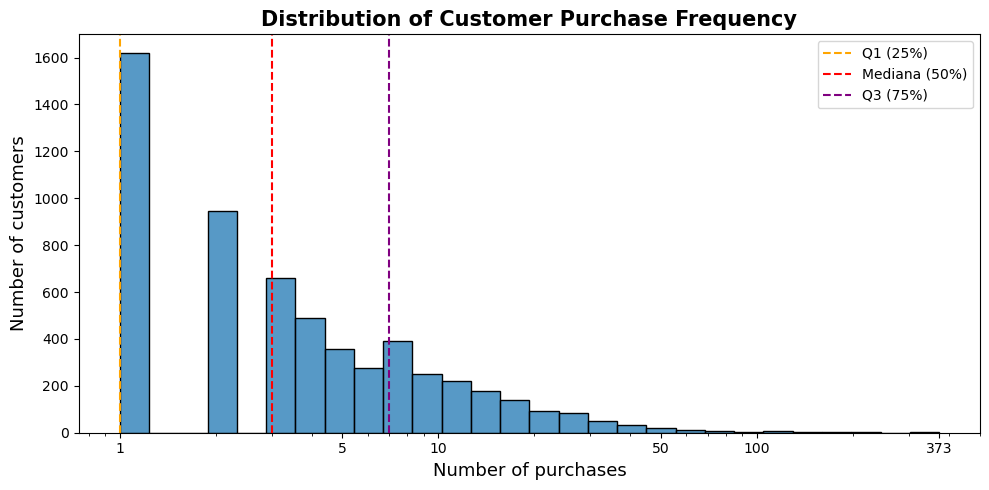

In [80]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rfm,
    x="Frequency",
    log_scale=True
)

plt.title("Distribution of Customer Purchase Frequency", fontsize=15, fontweight='bold') 
plt.xlabel("Number of purchases",fontsize=13) 
plt.ylabel('Number of customers',fontsize=13) 

# plt.xlim(0, rfm['Frequency'].quantile(0.95))
plt.xticks([1, 5, 10, 50, 100, 373], [1, 5, 10, 50, 100, 373])

plt.axvline(rfm['Frequency'].quantile(0.25), color='orange', linestyle='--', label='Q1 (25%)')
plt.axvline(rfm['Frequency'].quantile(0.50), color='red', linestyle='--', label='Mediana (50%)')
plt.axvline(rfm['Frequency'].quantile(0.75), color='purple', linestyle='--', label='Q3 (75%)')
plt.legend()

plt.tight_layout()
plt.show()

In [81]:
# Rozkład Frequency jest silnie prawoskośny - zdecydowana większość klientów (mediana = 3) dokonała zaledwie kilku zakupów w całym dwuletnim okresie.
# Jednocześnie niewielka grupa klientów wraca kilkadziesiąt, a nawet kilkaset razy (max = 373), co silnie odróżnia ją od typowego klienta.
#
# Taki rozkład sugeruje, że retencja w tym biznesie jest skoncentrowana wśród wąskiej grupy bardzo aktywnych klientów, podczas gdy większość
# dokonuje jednorazowego lub sporadycznego zakupu

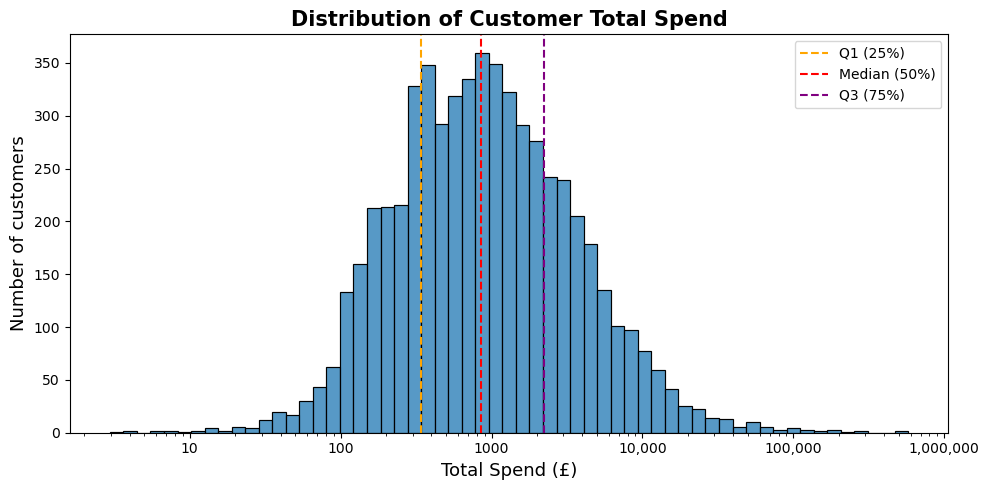

In [82]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rfm,
    x="Monetary",
    log_scale=True
)

plt.title("Distribution of Customer Total Spend", fontsize=15, fontweight='bold') 
plt.xlabel("Total Spend (£)",fontsize=13) 
plt.ylabel('Number of customers',fontsize=13) 


plt.xticks([10, 100, 1000, 10000, 100000, 1000000], ['10', '100', '1000', '10,000', '100,000', '1,000,000'])

plt.axvline(rfm['Monetary'].quantile(0.25), color='orange', linestyle='--', label='Q1 (25%)')
plt.axvline(rfm['Monetary'].quantile(0.50), color='red', linestyle='--', label='Median (50%)')
plt.axvline(rfm['Monetary'].quantile(0.75), color='purple', linestyle='--', label='Q3 (75%)')
plt.legend()

plt.tight_layout()
plt.show()

In [83]:
#Po zastosowaniu skali logarytmicznej rozkład Monetary staje się bardziej symetryczny. 
# #Ze względu na silną prawoskośność wartości Monetary wykorzystanie kwantyli pozwala lepiej podzielić klientów na grupy o podobnej liczebności.

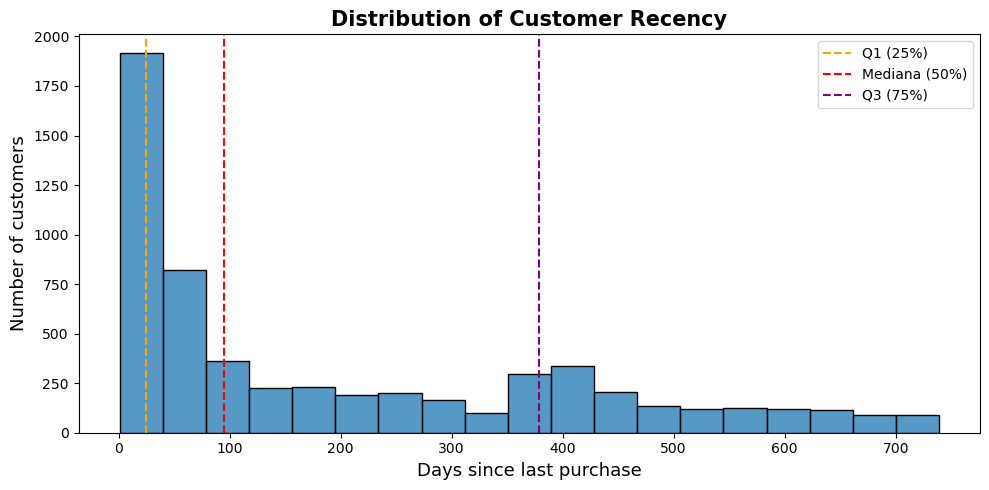

In [84]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rfm,
    x="Recency",
)

plt.title("Distribution of Customer Recency", fontsize=15, fontweight='bold') 
plt.xlabel("Days since last purchase",fontsize=13) 
plt.ylabel('Number of customers',fontsize=13) 


plt.axvline(rfm['Recency'].quantile(0.25), color='orange', linestyle='--', label='Q1 (25%)')
plt.axvline(rfm['Recency'].quantile(0.50), color='red', linestyle='--', label='Mediana (50%)')
plt.axvline(rfm['Recency'].quantile(0.75), color='purple', linestyle='--', label='Q3 (75%)')
plt.legend()

plt.tight_layout()
plt.show()

In [85]:
# Rozkład Recency jest dwumodalny - obok skupiska klientów z niską wartością Recency (kupowali niedawno przed końcem okresu obserwacji) widoczny jest
# drugi, wyraźny wzrost liczby klientów przy wysokich wartościach Recency (~300-450 dni).
#
# Taki kształt może wskazywać na współistnienie dwóch grup klientów: aktywnych, wracających regularnie, oraz tych, którzy zaprzestali zakupów
# i pozostają nieaktywni od dłuższego czasu. Określimy to w dalszej analizie 

In [86]:
rfm['F_score'] = pd.qcut(rfm['Frequency'], q=5,labels=[1,2,3,4], duplicates='drop')
rfm[['Frequency', 'F_score']].head(10)

,Frequency,F_score
Customer ID,,
12346.00,3,2
12347.00,8,3
12348.00,5,3
12349.00,3,2
12350.00,1,1
12351.00,1,1
12352.00,9,4
12353.00,2,1
12354.00,1,1


In [87]:
rfm['F_score'].value_counts().sort_index()

F_score
1    2563
2    1148
3    1025
4    1116
Name: count, dtype: int64

In [88]:
pd.qcut(rfm['Frequency'], q=5, duplicates='drop').value_counts()

Frequency
(0.999, 2.0]    2563
(2.0, 4.0]      1148
(8.0, 373.0]    1116
(4.0, 8.0]      1025
Name: count, dtype: int64

In [89]:
# Frequency scoring: użyto q=5 (standardowe kwintyle), ale ze względu na dużą liczbę klientów z identyczną, niską wartością Frequency (np. ponad 2500 
# klientów z 1-2 zakupami), część granic kwantylowych pokrywa się.
# Po odrzuceniu duplikatów (duplicates='drop') powstały 4 rozróżnialne poziomy zamiast 5 - co uczciwie odzwierciedla rzeczywistą granularność tego rozkładu.
# Wymuszenie 5 grup, robzija już istniejące grupy 2,3,4 na mniejsze w dalszym ciągu zostawijąć grupę F_score = 1 z liczebnością 2563.

In [90]:
rfm['R_score'] = pd.qcut(rfm['Recency'], q=5,labels=[5,4,3,2,1], duplicates='drop')
rfm['R_score'].value_counts().sort_index()

R_score
5    1187
4    1174
3    1155
2    1173
1    1163
Name: count, dtype: int64

In [91]:
# Odwróceno kolejności etykiet (5,4,3,2,1) dla Recency - w przeciwieństwie do Frequency i Monetary, niska wartość Recency jest korzystna,
# oznaczna niedawne zakupy klienta. Najwyższy score przypisujemy klientom z najniższą wartością Recency.

In [92]:
rfm['M_score'] = pd.qcut(rfm['Monetary'], q=5,labels=[1,2,3,4,5], duplicates='drop')
rfm['M_score'].value_counts().sort_index()

M_score
1    1171
2    1170
3    1170
4    1170
5    1171
Name: count, dtype: int64

 Sprawdzenie zakresów wartości dla poszczególnych wyników RFM

In [93]:
score_ranges = pd.concat([
    rfm.groupby('R_score')['Recency'].agg(Min='min', Max='max')
       .assign(Metric='Recency', Score=lambda x: x.index),
    
    rfm.groupby('F_score')['Frequency'].agg(Min='min', Max='max')
       .assign(Metric='Frequency', Score=lambda x: x.index),
    
    rfm.groupby('M_score')['Monetary'].agg(Min='min', Max='max')
       .assign(Metric='Monetary', Score=lambda x: x.index)
])

score_ranges = score_ranges[['Metric', 'Score', 'Min', 'Max']]
score_ranges

,Metric,Score,Min,Max
5,Recency,5,1.00,19.00
4,Recency,4,20.00,59.00
3,Recency,3,60.00,187.00
2,Recency,2,188.00,409.00
1,Recency,1,410.00,739.00
1,Frequency,1,1.00,2.00
2,Frequency,2,3.00,4.00
3,Frequency,3,5.00,8.00
4,Frequency,4,9.00,373.00
1,Monetary,1,2.95,285.30


In [94]:
rfm

,Last,Recency,Frequency,Monetary,F_score,R_score,M_score
Customer ID,,,,,,,
12346.00,2011-01-18 10:01:00,326,3,77352.96,2,2,5
12347.00,2011-12-07 15:52:00,2,8,4921.53,3,5,5
12348.00,2011-09-25 13:13:00,75,5,1658.40,3,3,4
12349.00,2011-11-21 09:51:00,19,3,3678.69,2,5,5
12350.00,2011-02-02 16:01:00,310,1,294.40,1,2,2
...,...,...,...,...,...,...,...
18283.00,2011-12-06 12:02:00,4,22,2658.95,4,5,4
18284.00,2010-10-04 11:33:00,432,1,411.68,1,1,2
18285.00,2010-02-17 10:24:00,661,1,377.00,1,1,2


In [95]:
print(rfm['R_score'].dtype)
print(rfm['F_score'].dtype)
print(rfm['M_score'].dtype)

category
category
category


In [96]:
rfm['R_score'] = rfm['R_score'].astype(int)
rfm['F_score'] = rfm['F_score'].astype(int)
rfm['M_score'] = rfm['M_score'].astype(int)

In [97]:
print(rfm['R_score'].value_counts().sort_index())
print(rfm['F_score'].value_counts().sort_index())
print(rfm['M_score'].value_counts().sort_index())

R_score
1    1163
2    1173
3    1155
4    1174
5    1187
Name: count, dtype: int64
F_score
1    2563
2    1148
3    1025
4    1116
Name: count, dtype: int64
M_score
1    1171
2    1170
3    1170
4    1170
5    1171
Name: count, dtype: int64


In [98]:
pd.crosstab(rfm['R_score'], rfm['F_score'])

F_score,1,2,3,4
R_score,,,,
1,944,150,53,16
2,684,273,167,49
3,420,281,274,180
4,320,259,279,316
5,195,185,252,555


In [99]:
pd.crosstab(rfm['R_score'], rfm['M_score'])

M_score,1,2,3,4,5
R_score,,,,,
1,506,338,182,101,36
2,303,332,282,183,73
3,163,220,259,310,203
4,132,164,248,298,332
5,67,116,199,278,527


In [100]:
pd.crosstab(rfm['F_score'], rfm['M_score'])

M_score,1,2,3,4,5
F_score,,,,,
1,1126,892,409,114,22
2,41,247,502,304,54
3,3,30,242,527,223
4,1,1,17,225,872


Segmentacja 
Na podstawie powyższych obserwacji budejmy progi do segmentów klientów. 

In [101]:
r, f, m = rfm['R_score'], rfm['F_score'], rfm['M_score']

conditions = [
    (r >= 4) & (f >= 3) & (m >= 4),               # Champions
    (r >= 3) & (f >= 3) & (m >= 3),               # Loyal Customers
    (r == 5) & (f == 1),                          # Recent / Low-Frequency
    (r >= 4) & (f.isin([2, 3])) & (m <= 3),       # Potential Loyalists
    (r <= 2) & (f >= 3) & (m >= 3),               # At Risk 
    (r <= 2) & (f <= 2) & (m <= 2),               # Hibernating/Lost
]

segment_names = [
    "Champions",
    "Loyal Customers",
    "Recent / Low-Frequency",
    "Potential Loyalists",
    "At Risk",
    "Hibernating/Lost",
]

rfm['Segment'] = np.select(conditions, segment_names, default="Others")

rfm['Segment'].value_counts()

Segment
Others                    1768
Hibernating/Lost          1465
Champions                 1265
Loyal Customers            570
Potential Loyalists        318
At Risk                    271
Recent / Low-Frequency     195
Name: count, dtype: int64

In [102]:
rfm.loc[rfm['Segment'] == 'Others',
        ['R_score', 'F_score', 'M_score']].value_counts().sort_index()

R_score  F_score  M_score
1        1        3          103
                  4           30
                  5            8
         2        3           66
                  4           37
                  5            9
         3        1            1
                  2            2
2        1        3          103
                  4           28
                  5            4
         2        3          124
                  4           66
                  5            8
         3        2           11
3        1        1          150
                  2          150
                  3           87
                  4           29
                  5            4
         2        1           11
                  2           63
                  3          106
                  4           83
                  5           18
         3        1            1
                  2            7
         4        1            1
4        1        1          120
                 

## Weryfikacja i korekta reguł segmentacji

Po zbudowaniu pierwszej wersji segmentacji (6 grup na bazie tabel R×F, R×M, F×M) 
sprawdzono skład grupy `Others` (ok. 30% klientów) i wprowadzono korekty:

- **Hibernating/Lost** - usunięto ograniczenie na Monetary. Przy 2-letnim okresie 
  obserwacji klient nieaktywny i rzadko kupujący jest potencjalnie uznawany za utraconego 
  niezależnie od tego, ile wydał przy okazjonalnych zakupach.
- **Recent / Low-Frequency** - rozszerzono Recency z `R=5` na `R∈[4,5]` i usunięto 
  warunek na Monetary. Klient z pojedynczym, niedawnym zakupem jest "nowy" 
  niezależnie od jego wartości - do Others trafiali wartościowi, świeżo 
  pozyskani klienci (np. R=4, F=1, M=4), którzy powinni należeć tu, nie do Others.
- **Champions** - dostosowano próg Frequency do rzeczywistej skali (`F=4`, 
  nie `F≥3`), ponieważ Frequency ma tylko 4 poziomy (vs 5 dla R i M), 
  a `F≥3` obejmowałoby połowę skali - zbyt szeroko jak na segment "najlepszych".
- **Potential Loyalists** - zawężono do `F=2` (nie `F∈[2,3]`), ponieważ klienci 
  z `F=3` spełniający też `R≥3` i `M≥3` są już przechwytywani przez wcześniejszą 
  regułę Loyal Customers - dzięki kolejności i zastoswoaniu `np.select`.

Niewyodrębniono osobnej grupy "Can't Lose Them" (ekstremalny 
przypadek At Risk, ~16 klientów) posiada zbyt małą liczebność do 
wiarygodnych wniosków oraz nie posiada realnej różnicy w rekomendowanym działaniu 
marketingowym względem szerszej grupy At Risk.

In [103]:
r, f, m = rfm['R_score'], rfm['F_score'], rfm['M_score']

conditions = [
    (r >= 4) & (f == 4) & (m >= 4),              # Champions
    (r >= 3) & (f >= 3) & (m >= 3),              # Loyal Customers
    (r.isin([4, 5])) & (f == 1),                 # Recent / Low-Frequency
    (r >= 3) & (f == 2) & (m >= 3),              # Potential Loyalists
    (r <= 2) & (f >= 3) & (m >= 3),              # At Risk
    (r <= 2) & (f <= 2),                         # Hibernating/Lost
]

segment_names = [
    "Champions",
    "Loyal Customers",
    "Recent / Low-Frequency",
    "Potential Loyalists",
    "At Risk",
    "Hibernating/Lost",
]

rfm['Segment'] = np.select(conditions, segment_names, default="Others")
rfm['Segment'].value_counts()

Segment
Hibernating/Lost          2051
Loyal Customers            971
Champions                  864
Others                     630
Potential Loyalists        550
Recent / Low-Frequency     515
At Risk                    271
Name: count, dtype: int64

In [104]:
rfm.loc[rfm['Segment'] == 'Others',
        ['R_score', 'F_score', 'M_score']].value_counts().sort_index()

R_score  F_score  M_score
1        3        1            1
                  2            2
2        3        2           11
3        1        1          150
                  2          150
                  3           87
                  4           29
                  5            4
         2        1           11
                  2           63
         3        1            1
                  2            7
         4        1            1
4        2        1           11
                  2           52
         3        1            1
                  2            4
5        2        1            6
                  2           32
         3        2            6
         4        2            1
Name: count, dtype: int64

Kategorię Other można podzielić na dwie podgrupy: 

* Klienci, którzy charakteryzują się stosunkowo niedawną aktywnością, ale o niskiej częstotliwości (w większości do 2 zakupów) i wartości zakupów w większości skoncetrowanej na niskiej wartości ale z rozpiętością na całą skalę monetary. (420 klientów)

* Klienci, którzy byli aktywni w większości maksymalnie do pół roku od konca okresu, dokonując minimum 3 zakupów o niskiej wartości zakupów. (210 klientów)

To grupa z potencjałem do dalszego zaangażowania, która nie wykształciła jeszcze wyraźnych wzorców lojalności lub regularnych zakupów. Finalnie określimy ją jako 'Needs Attention'.

In [105]:
rfm['Segment'] = rfm['Segment'].replace('Others', 'Needs Attention')

In [106]:
segment_summary = rfm.groupby('Segment').agg(Customers=('Recency','size'),
                           Median_Recency=('Recency','median'),
                           Median_Frequency=('Frequency','median'),
                           Median_Monetary=('Monetary','median'),
                           Total_Revenue=('Monetary','sum')
                           ).reset_index().sort_values('Customers',ascending=False)
segment_summary

,Segment,Customers,Median_Recency,Median_Frequency,Median_Monetary,Total_Revenue
2,Hibernating/Lost,2051,418.00,1.00,350.35,1265338.62
3,Loyal Customers,971,52.00,7.00,2064.71,2816944.28
1,Champions,864,13.00,15.00,5461.39,10472277.37
4,Needs Attention,630,86.00,2.00,411.09,312567.43
5,Potential Loyalists,550,43.00,3.00,1112.65,812011.80
6,Recent / Low-Frequency,515,26.00,2.00,381.97,447737.77
0,At Risk,271,323.00,6.00,1826.00,941705.45


In [107]:
segment_summary['Pct_Customers'] = round((segment_summary['Customers']/len(rfm))*100,2)


In [108]:
segment_summary['Pct_Revenue'] = round((segment_summary['Total_Revenue']/rfm['Monetary'].sum())*100,2)


In [109]:
segment_summary = segment_summary[
    [
        'Segment',
        'Customers',
        'Pct_Customers',
        'Median_Recency',
        'Median_Frequency',
        'Median_Monetary',
        'Total_Revenue',
        'Pct_Revenue'
    ]
]
segment_summary

,Segment,Customers,Pct_Customers,Median_Recency,Median_Frequency,Median_Monetary,Total_Revenue,Pct_Revenue
2,Hibernating/Lost,2051,35.05,418.00,1.00,350.35,1265338.62,7.41
3,Loyal Customers,971,16.59,52.00,7.00,2064.71,2816944.28,16.50
1,Champions,864,14.76,13.00,15.00,5461.39,10472277.37,61.35
4,Needs Attention,630,10.77,86.00,2.00,411.09,312567.43,1.83
5,Potential Loyalists,550,9.40,43.00,3.00,1112.65,812011.80,4.76
6,Recent / Low-Frequency,515,8.80,26.00,2.00,381.97,447737.77,2.62
0,At Risk,271,4.63,323.00,6.00,1826.00,941705.45,5.52


In [110]:
segment_long = pd.melt(
    segment_summary.sort_values('Pct_Revenue', ascending=False),
    id_vars='Segment',
    value_vars=['Pct_Revenue','Pct_Customers'],
    var_name='Metric',
    value_name='Value'
)

In [111]:
segment_long

,Segment,Metric,Value
0,Champions,Pct_Revenue,61.35
1,Loyal Customers,Pct_Revenue,16.50
2,Hibernating/Lost,Pct_Revenue,7.41
3,At Risk,Pct_Revenue,5.52
4,Potential Loyalists,Pct_Revenue,4.76
5,Recent / Low-Frequency,Pct_Revenue,2.62
6,Needs Attention,Pct_Revenue,1.83
7,Champions,Pct_Customers,14.76
8,Loyal Customers,Pct_Customers,16.59
9,Hibernating/Lost,Pct_Customers,35.05


In [112]:
segment_long['Metric'] = segment_long['Metric'].replace({
    'Pct_Customers': '% Customers',
    'Pct_Revenue': '% Revenue'
})

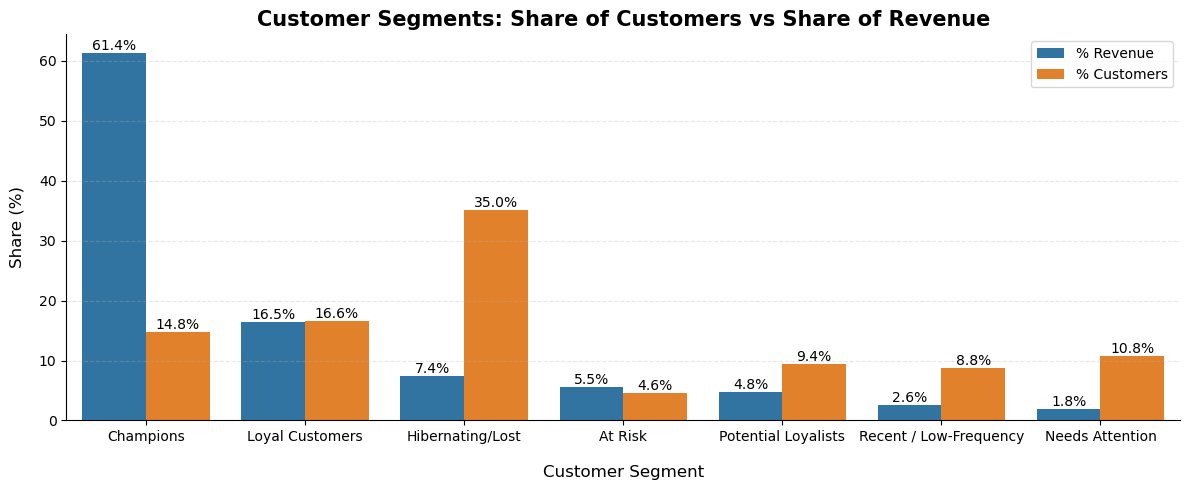

In [113]:
plt.figure(figsize=(12, 5))

ax = sns.barplot(
    data=segment_long,
    x="Segment",
    y="Value",
    hue = 'Metric'
)

plt.title("Customer Segments: Share of Customers vs Share of Revenue", fontsize=15, fontweight='bold')
plt.xlabel("Customer Segment",fontsize=12, labelpad=15)
plt.ylabel("Share (%)",fontsize=12, labelpad=10)
plt.grid(axis='y', alpha=0.3, linestyle='--')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', fontsize=10)

sns.despine()
plt.legend(title='')
plt.tight_layout()
plt.show()

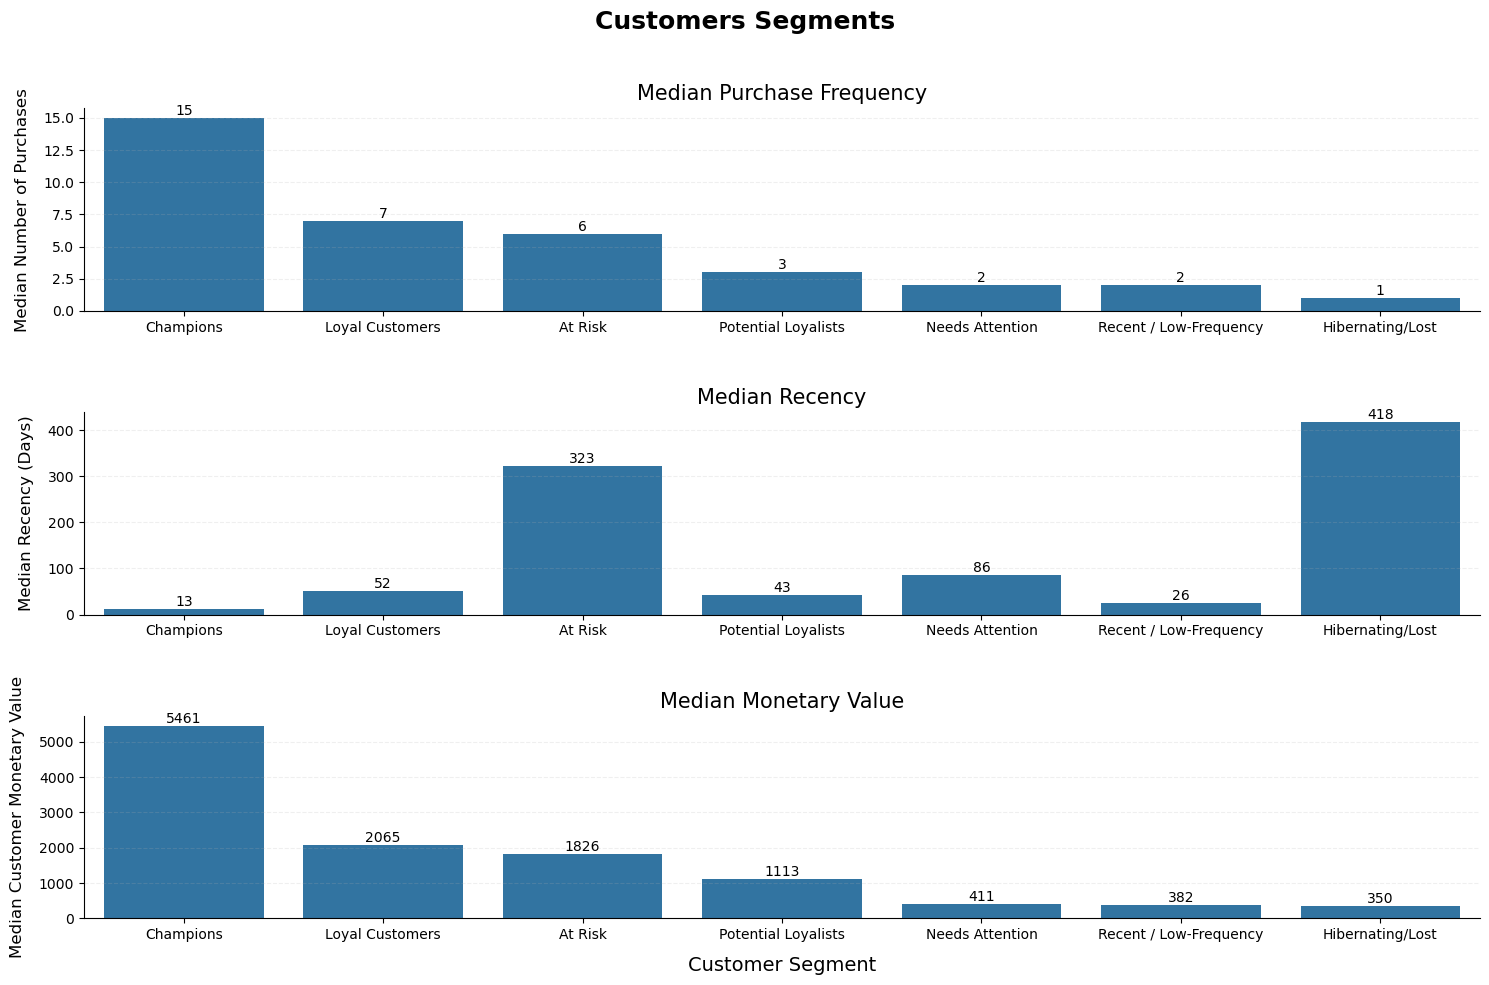

In [114]:
fig, axes = plt.subplots(3, 1, figsize=(15, 10))

fig.suptitle('Customers Segments', fontsize=18, fontweight='bold')
sns.barplot(
    data=segment_summary.sort_values(by='Median_Monetary',ascending=False),
    x="Segment",
    y="Median_Frequency",
    ax = axes[0]
)

axes[0].set_title("Median Purchase Frequency", fontsize=15)
axes[0].set_xlabel("")
axes[0].set_ylabel("Median Number of Purchases",fontsize=12, labelpad=10)
axes[0].grid(axis='y', alpha=0.2, linestyle='--')
axes[0].bar_label(axes[0].containers[0])


sns.barplot(
    data=segment_summary.sort_values(by='Median_Monetary',ascending=False),
    x="Segment",
    y="Median_Recency",
    ax= axes[1]
)

axes[1].set_title("Median Recency", fontsize=15)
axes[1].set_xlabel("")
axes[1].set_ylabel("Median Recency (Days)",fontsize=12, labelpad=10)
axes[1].grid(axis='y', alpha=0.2, linestyle='--')
axes[1].bar_label(axes[1].containers[0])


sns.barplot(
    data=segment_summary.sort_values(by='Median_Monetary',ascending=False),
    x="Segment",
    y="Median_Monetary",
    ax = axes[2]
)

axes[2].set_title("Median Monetary Value", fontsize=15)
axes[2].set_xlabel("Customer Segment",fontsize=14, labelpad=10)
axes[2].set_ylabel("Median Customer Monetary Value",fontsize=12, labelpad=10)
axes[2].grid(axis='y', alpha=0.2, linestyle='--')
axes[2].bar_label(axes[2].containers[0], fmt='%.0f')


sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.subplots_adjust(hspace=0.5)

In [115]:
segment_order = segment_summary.sort_values(
        'Median_Monetary',
        ascending=False
    )['Segment']

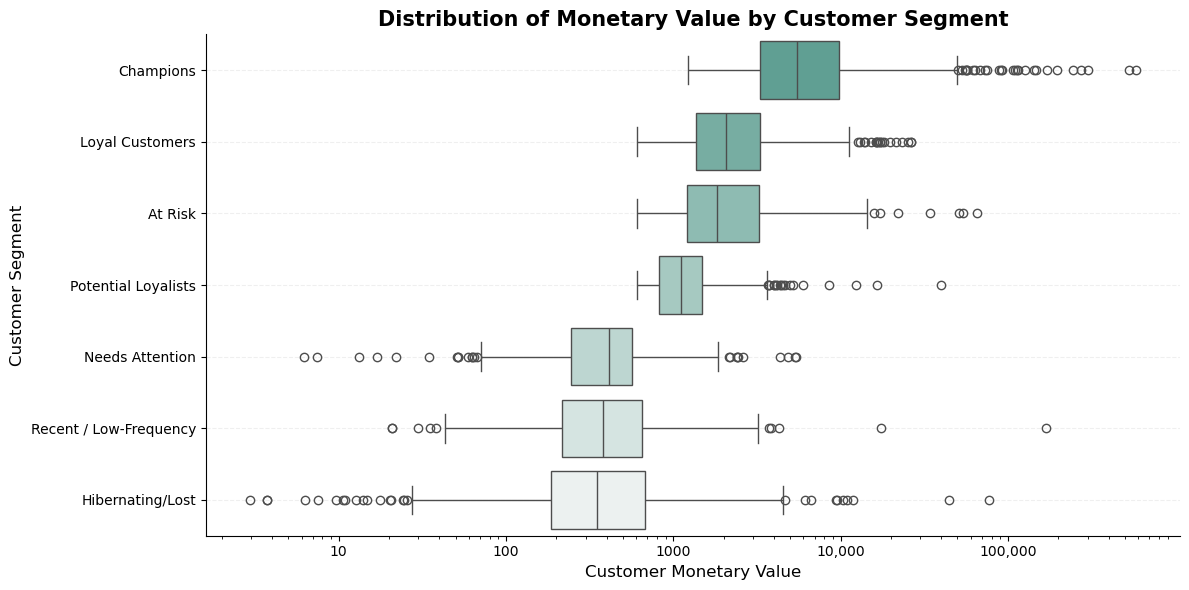

In [116]:
plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=rfm,
    x='Monetary',
    y='Segment',
    hue = 'Segment',
    hue_order= segment_order,
    order=segment_order,
    log_scale=True,
    palette="light:#5A9_r",
    legend= False
)
plt.xticks([10, 100, 1000, 10000, 100000], ['10', '100', '1000', '10,000', '100,000'])
plt.title('Distribution of Monetary Value by Customer Segment', fontsize=15, fontweight='bold')
plt.ylabel('Customer Segment',fontsize=12)
plt.xlabel('Customer Monetary Value',fontsize=12)
plt.grid(axis='y', alpha=0.2, linestyle='--')

sns.despine()
plt.tight_layout()
plt.show()

Boxplot pokazuje duże zróżnicowanie wartości Monetary wewnątrz poszczególnych segmentów oraz obecność licznych obserwacji odstających. Widoczna jest wyraźna progresja — segmenty o wyższej medianie wartości zakupów, szczególnie Champions i Loyal Customers, mają bardziej skoncentrowany rozkład wartości, podczas gdy segmenty o niższej medianie charakteryzują się większym rozrzutem wartości klientów.

Szczególnie interesujące są liczne wartości odstające występujące również w słabszych segmentach, sięgające nawet 100 000+ funtów. Pokazuje to, że nawet w segmentach o niskiej medianie Monetary występują pojedynczy klienci o bardzo wysokiej historycznej wartości zakupów. Mediana nie pokazuje więc pełnego zróżnicowania wartości wewnątrz segmentów.

---

## Charakterystyka segmentów

Charakterystyka poszczególnych segmentów została przygotowana na podstawie median wartości RFM, dzięki czemu opisuje typowego klienta w danej grupie i ogranicza wpływ pojedynczych skrajnych obserwacji.

* Champions: typowy klient w tym segmencie dokonał 15 zakupów o łącznej wartości około 5 400 GBP. Jest to najbardziej aktywna i wartościowa grupa klientów — mediana Recency wynosi zaledwie 13 dni, co oznacza, że połowa klientów z tego segmentu dokonała ostatniego zakupu w ciągu 13 dni od końca badanego okresu.

* Loyal Customers: typowy klient dokonał 7 zakupów o łącznej wartości około 2 065 GBP. Jest to profil wyraźnie słabszy od Champions zarówno pod względem częstotliwości, jak i wartości zakupów, jednak nadal charakteryzuje się wysokim poziomem zaangażowania. Mediana Recency wynosi 52 dni, czyli połowa klientów z tego segmentu dokonała zakupu w ciągu ostatnich 52 dni badanego okresu. Łączna wartość sprzedaży wygenerowana przez ten segment wynosi około 26% wartości wygenerowanej przez Champions.

* Potential Loyalists: typowy klient dokonał 3 zakupów o łącznej wartości około 1 113 GBP, a jego ostatni zakup miał miejsce 43 dni przed końcem badanego okresu. Jest to grupa o niższej częstotliwości i wartości zakupów niż Loyal Customers, ale jednocześnie relatywnie świeża. Segment może więc obejmować klientów, którzy zaczęli już powtarzać zakupy, ale nie osiągnęli jeszcze poziomu zaangażowania charakterystycznego dla bardziej wartościowych segmentów.

* At Risk: jest to niewielka grupa, ale wyróżniająca się wysoką historyczną wartością zakupów. Typowy klient dokonał 6 zakupów o łącznej wartości około 1 826 GBP, czyli wartości zbliżonej do Loyal Customers (2 065 GBP) i tylko nieco niższej częstotliwości (6 vs 7 zakupów). Jednocześnie mediana Recency wynosi aż 323 dni. Oznacza to, że połowa klientów w tym segmencie dokonała ostatniego zakupu około 10,5 miesiąca wcześniej. Jest to więc grupa klientów, która historycznie wykazywała istotne zaangażowanie, ale obecnie pozostaje nieaktywna.

* Recent / Low-Frequency: typowy klient dokonał 2 zakupów o łącznej wartości około 382 GBP, a mediana Recency wynosi 26 dni. Jest to więc grupa klientów stosunkowo niedawno aktywnych, ale charakteryzujących się jeszcze niewielką częstotliwością i wartością zakupów. W porównaniu z pozostałymi segmentami jest to profil klienta o niskim obecnym zaangażowaniu, ale z relatywnie świeżym kontaktem ze sklepem.

* Needs Attention: typowy klient dokonał 2 zakupów o łącznej wartości około 411 GBP, a mediana Recency wynosi 86 dni. Pod względem częstotliwości i wartości zakupów segment jest zbliżony do Recent / Low-Frequency, jednak klienci są mniej aktywni — ostatni zakup miał miejsce medianowo 86 dni wcześniej, wobec 26 dni w przypadku Recent / Low-Frequency. Segment ten obejmuje klientów o niskim poziomie zaangażowania, którzy nie spełniają kryteriów pozostałych głównych segmentów.

* Hibernating / Lost: jest to segment o najniższym poziomie aktywności i wartości zakupów. Mediana Recency wynosi 418 dni, a więc połowa klientów dokonała ostatniego zakupu ponad rok przed końcem badanego okresu. Mediana Frequency wynosi 1 zakup, a mediana Monetary około 350 GBP. Jest to więc grupa klientów o bardzo niskim historycznym zaangażowaniu, która obecnie pozostaje nieaktywna. Ze względu na charakter segmentacji określam ją jako potencjalnie utraconą, ponieważ sam RFM nie pozwala stwierdzić, czy klient definitywnie zakończył relację ze sklepem.

## Podsumowanie segmentacji RFM

Największym segmentem klientów są Hibernating / Lost, którzy stanowią 35,1% całej bazy. Kolejne pod względem liczebności są Champions (14,8%) i Loyal Customers (16,6%), natomiast najmniejszą grupę stanowią klienci At Risk (4,6%).

Najważniejszym wnioskiem z segmentacji jest jednak nie sama liczebność grup, ale silna koncentracja wartości sprzedaży wśród najbardziej zaangażowanych klientów. Champions stanowią 14,8% klientów, ale odpowiadają za 61,4% wartości sprzedaży. Po połączeniu Champions i Loyal Customers otrzymujemy 31,4% klientów generujących łącznie 77,9% wartości sprzedaży. Jest to wyraźna koncentracja wartości w relatywnie niewielkiej części bazy, choć nie należy traktować jej jako dokładnego potwierdzenia klasycznej zasady Pareto 80/20.

Odwrotną sytuację obserwujemy w przypadku Hibernating / Lost. Jest to najliczniejszy segment, obejmujący 35,1% klientów, ale odpowiadający jedynie za 7,4% wartości sprzedaży. Oznacza to, że duża część bazy ma obecnie niewielkie znaczenie z punktu widzenia historycznej wartości zakupów.

Szczególnie interesującą grupą jest At Risk. Mimo że obejmuje tylko 4,6% klientów, jej mediana Frequency (6 zakupów) i Monetary (1 826 GBP) jest zbliżona do Loyal Customers (7 zakupów i 2 065 GBP). Jednocześnie mediana Recency wynosi aż 323 dni, co pokazuje wyraźny rozdźwięk pomiędzy wcześniejszą wartością tych klientów a ich obecną aktywnością.

Pozostałe segmenty pokazują natomiast klientów znajdujących się pomiędzy tymi skrajnymi profilami — od stosunkowo świeżych, ale jeszcze mało aktywnych klientów po klientów o większej historii zakupowej, których aktywność zaczyna wygasać. RFM pozwala więc wskazać nie tylko najbardziej wartościowych klientów, ale również grupy, w których wartość historyczna i obecna aktywność wyraźnie się rozchodzą.

---

## Analiza kohortowa

Jak zmieniało się zachowanie klientów pozyskiwanych w różnych okresach i czy sezon, moment pozyskania oraz typ zakupów wpływały na ich skłonność do powrotu?

In [117]:
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom,30.00


In [118]:
cohorts = df_clean.groupby('Customer ID').agg(First=('InvoiceDate','min'))
cohorts

,First
Customer ID,
12346.00,2010-03-02 13:08:00
12347.00,2010-10-31 14:20:00
12348.00,2010-09-27 14:59:00
12349.00,2010-04-29 13:20:00
12350.00,2011-02-02 16:01:00
...,...
18283.00,2010-02-19 17:16:00
18284.00,2010-10-04 11:33:00
18285.00,2010-02-17 10:24:00


In [119]:
cohorts['CohortMonth'] = cohorts['First'].dt.to_period('M')
cohorts = cohorts.reset_index()
cohorts

,Customer ID,First,CohortMonth
0,12346.00,2010-03-02 13:08:00,2010-03
1,12347.00,2010-10-31 14:20:00,2010-10
2,12348.00,2010-09-27 14:59:00,2010-09
3,12349.00,2010-04-29 13:20:00,2010-04
4,12350.00,2011-02-02 16:01:00,2011-02
...,...,...,...
5847,18283.00,2010-02-19 17:16:00,2010-02
5848,18284.00,2010-10-04 11:33:00,2010-10
5849,18285.00,2010-02-17 10:24:00,2010-02
5850,18286.00,2009-12-16 10:45:00,2009-12


In [120]:
new_customers_by_month = (
    cohorts
    .groupby('CohortMonth')['Customer ID']
    .nunique()
)

### Wykres wielkości kohort 

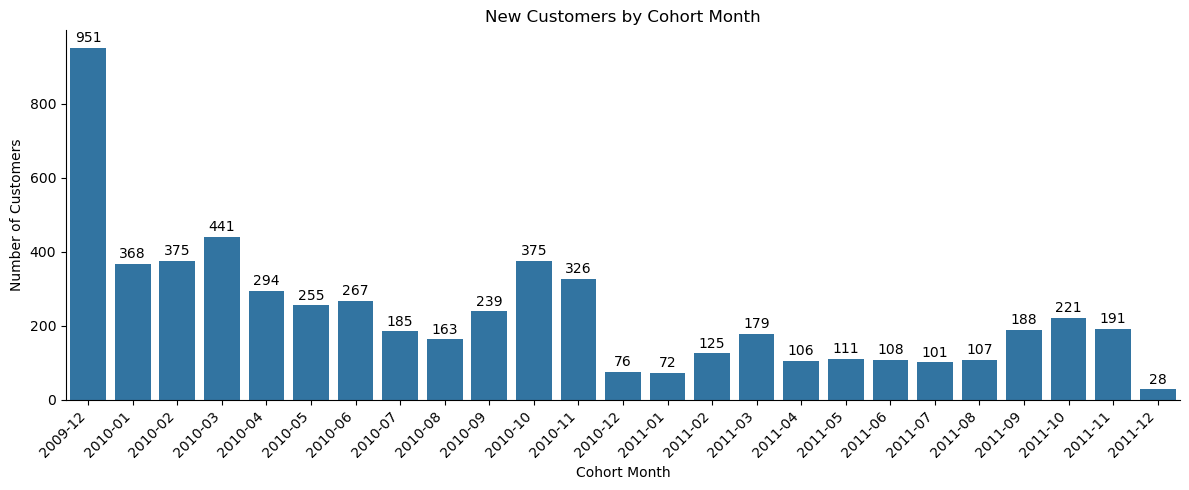

In [121]:
plt.figure(figsize=(12, 5))

ax = sns.barplot(
    x=new_customers_by_month.index.astype(str),
    y=new_customers_by_month.values
)

ax.bar_label(ax.containers[0], fmt='%.0f', padding=2)

plt.title('New Customers by Cohort Month')
plt.xlabel('Cohort Month')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45, ha= 'right')

sns.despine()
plt.tight_layout()
plt.show()

Wielkość kohorty z grudnia 2009 może być sztucznie zawyżona. To pierwszy miesiąc dostępnych danych, więc obejmuje wszystkich klientów aktywnych na początku obserwacji, niezależnie od tego, kiedy faktycznie rozpoczęli relację z firmą. Część z nich mogła być klientami już przed rozpoczęciem obserwacji. Sugestia ta wynika również z faktu, że kohorta 2009-12 jest ponad dwukrotnie większa od drugiej najliczniejszej kohorty i żadna z pozostałych kohort nie osiąga zbliżonej wielkości.

Podobnie grudzień 2011 nie przedstawia pełnego obrazu pozyskania klientów, ponieważ dane obejmują tylko okres do 9 grudnia 2011.

Analiza pokazuje wyraźny spadek liczby nowych klientów. W okresie styczeń–listopad 2010 pozyskano 3288 klientów, podczas gdy w analogicznym okresie 2011 było ich 1509, co oznacza spadek o około 54%. Jest to istotny sygnał biznesowy wymagający dalszej analizy.

Ponadto możemy zaobserwować prawdopodobny wzorzec sezonowy w pozyskiwaniu klientów. Wzrost liczby nowych klientów obserwowany w lutym–marcu oraz ponownie od sierpnia do listopada wskazuje na zwiększoną akwizycję w okresach poprzedzających główne sezony świąteczne — odpowiednio Wielkanoc oraz Boże Narodzenie. Wzorzec ten jest zgodny z charakterystyką datasetu, obejmującego sprzedaż artykułów prezentowych, oraz informacją, że znaczną część klientów stanowią hurtownicy.

Dokładne przypisanie obserwowanych wzrostów do konkretnych okresów świątecznych wymagałoby dodatkowej weryfikacji na poziomie porównania analogicznych miesięcy w kolejnych latach na szerszym zbiorze danych.

In [122]:
df_cohort = df_clean.copy()

In [123]:
df_cohort = df_cohort.merge(cohorts[['Customer ID','CohortMonth']], on='Customer ID')

In [124]:
df_cohort['InvoiceMonth'] = df_cohort['InvoiceDate'].dt.to_period('M')

In [125]:
df_cohort['CohortIndex'] = df_cohort['InvoiceMonth'].astype(int) - df_cohort['CohortMonth'].astype(int)

In [126]:
df_cohort['CohortIndex'].describe()

count   776579.00
mean         8.08
std          7.22
min          0.00
25%          1.00
50%          7.00
75%         13.00
max         24.00
Name: CohortIndex, dtype: float64

In [127]:
cohort_table = df_cohort.pivot_table(
    index='CohortMonth',
    columns='CohortIndex',
    values='Customer ID',
    aggfunc='nunique'
)
cohort_table

CohortIndex,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,951.00,333.00,317.00,404.00,360.00,342.00,358.00,327.00,321.00,344.00,...,288.00,250.00,288.00,270.00,246.00,242.00,298.00,289.00,386.00,187.00
2010-01,368.00,79.00,118.00,116.00,100.00,114.00,99.00,86.00,105.00,120.00,...,56.00,90.00,75.00,71.00,74.00,93.00,73.00,93.00,21.00,NaN
2010-02,375.00,88.00,85.00,110.00,92.00,74.00,72.00,108.00,96.00,104.00,...,75.00,60.00,61.00,54.00,86.00,86.00,62.00,22.00,NaN,NaN
2010-03,441.00,84.00,102.00,107.00,102.00,90.00,109.00,135.00,122.00,48.00,...,75.00,77.00,69.00,78.00,90.00,94.00,34.00,NaN,NaN,NaN
2010-04,294.00,56.00,56.00,47.00,54.00,65.00,81.00,78.00,31.00,32.00,...,46.00,41.00,44.00,53.00,67.00,17.00,NaN,NaN,NaN,NaN
2010-05,255.00,40.00,43.00,45.00,45.00,65.00,54.00,32.00,15.00,21.00,...,32.00,35.00,42.00,39.00,12.00,NaN,NaN,NaN,NaN,NaN
2010-06,267.00,47.00,50.00,55.00,62.00,76.00,34.00,24.00,22.00,30.00,...,33.00,35.00,54.00,13.00,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,185.00,29.00,34.00,55.00,54.00,26.00,21.00,27.00,27.00,21.00,...,32.00,44.00,15.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,163.00,32.00,47.00,53.00,27.00,19.00,16.00,21.00,22.00,21.00,...,32.00,12.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Cohort Index 0 oznacza miesiąc pierwszego zakupu, a każdy kolejny indeks oznacza następny miesiąc kalendarzowy od momentu pozyskania klienta.

In [128]:
retention_table = cohort_table.divide(cohort_table[0], axis=0)
retention_table.round(3)

CohortIndex,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,1.00,0.35,0.33,0.42,0.38,0.36,0.38,0.34,0.34,0.36,...,0.30,0.26,0.30,0.28,0.26,0.25,0.31,0.30,0.41,0.20
2010-01,1.00,0.21,0.32,0.32,0.27,0.31,0.27,0.23,0.28,0.33,...,0.15,0.24,0.20,0.19,0.20,0.25,0.20,0.25,0.06,NaN
2010-02,1.00,0.23,0.23,0.29,0.24,0.20,0.19,0.29,0.26,0.28,...,0.20,0.16,0.16,0.14,0.23,0.23,0.17,0.06,NaN,NaN
2010-03,1.00,0.19,0.23,0.24,0.23,0.20,0.25,0.31,0.28,0.11,...,0.17,0.17,0.16,0.18,0.20,0.21,0.08,NaN,NaN,NaN
2010-04,1.00,0.19,0.19,0.16,0.18,0.22,0.28,0.27,0.10,0.11,...,0.16,0.14,0.15,0.18,0.23,0.06,NaN,NaN,NaN,NaN
2010-05,1.00,0.16,0.17,0.18,0.18,0.26,0.21,0.12,0.06,0.08,...,0.12,0.14,0.17,0.15,0.05,NaN,NaN,NaN,NaN,NaN
2010-06,1.00,0.18,0.19,0.21,0.23,0.28,0.13,0.09,0.08,0.11,...,0.12,0.13,0.20,0.05,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,1.00,0.16,0.18,0.30,0.29,0.14,0.11,0.15,0.15,0.11,...,0.17,0.24,0.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,1.00,0.20,0.29,0.33,0.17,0.12,0.10,0.13,0.14,0.13,...,0.20,0.07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [129]:
last_full_month = df_clean['InvoiceDate'].max().to_period('M') - 1

retention_table_masked = retention_table.copy()

for cohort in retention_table_masked.index:
    cohort_period = pd.Period(cohort, freq='M')
    max_valid_index = last_full_month.ordinal - cohort_period.ordinal

    retention_table_masked.loc[
        cohort,
        retention_table_masked.columns > max_valid_index
    ] = np.nan

In [130]:
retention_table_masked.loc['2011-12', 0] = np.nan

Ze względu na niepełny miesiąc obserwacji w grudniu 2011, dodano maskę usuwające wyniki liczone dla tego miesiąca. 

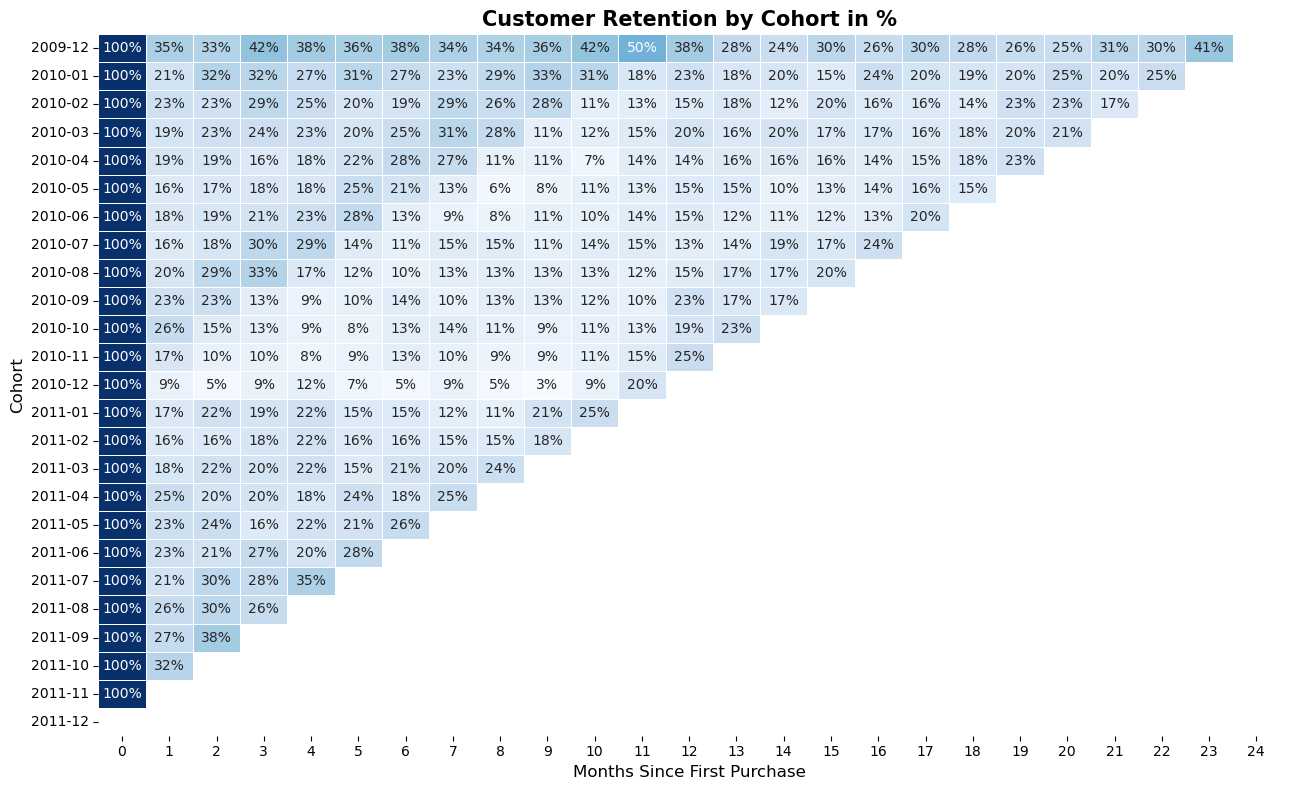

In [147]:
plt.figure(figsize=(13, 8))

sns.heatmap(
    retention_table_masked,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar= False,
)

plt.title("Customer Retention by Cohort in %", fontsize=15, fontweight='bold')
plt.xlabel("Months Since First Purchase", fontsize=12)
plt.ylabel("Cohort", fontsize=12)

plt.tight_layout()
plt.show()

Z analizy retencji wynika, że utrzymanie klientów po pierwszym zakupie jest na relatywnie niskim poziomie i charakteryzuje się dużym zróżnicowaniem pomiędzy kohortami. W kolejnych miesiącach retencja najczęściej utrzymuje się na poziomie około 10–20%, jednak nie obserwujemy stałego, monotonicznego spadku. W wielu kohortach pojawiają się okresowe wzrosty aktywności, co wskazuje, że część klientów powraca do sklepu po okresach braku zakupów.

Szczególnie wyróżnia się kohorta grudzień 2009, która przez znaczną część badanego okresu utrzymuje wyższą retencję niż większość pozostałych kohort, osiągając nawet 50% w 11. miesiącu. Wynik ten należy jednak traktować jako specyfikę tej kohorty, a nie ogólną tendencję. Jak wskazano wcześniej, kohorta ta obejmuje pierwszy miesiąc obserwacji i może zawierać klientów, którzy rozpoczęli relację z firmą przed rozpoczęciem dostępnego okresu danych.

Nowsze kohorty mają krótszy dostępny okres obserwacji, dlatego nie można ich bezpośrednio porównywać ze starszymi kohortami w późniejszych miesiącach cyklu życia. Szczególną ostrożność należy zachować przy kohortach z końca badanego okresu.


---

## Wykres M1 retention


In [132]:
m1_retention = retention_table_masked[1].dropna()

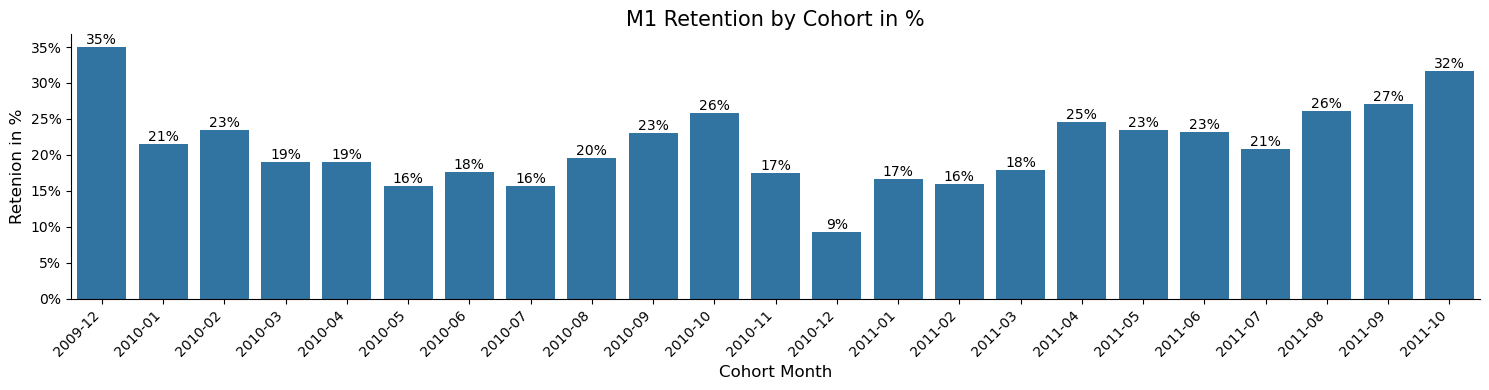

In [133]:
plt.figure(figsize=(15,4))

ax = sns.barplot(
    x=m1_retention.index,
    y= m1_retention.values
            )

for container in ax.containers:
    ax.bar_label(container, fmt= lambda x: f'{x*100:.0f}%', fontsize=10)

plt.title('M1 Retention by Cohort in %', fontsize= 15)
plt.xlabel('Cohort Month', fontsize= 12)
plt.ylabel('Retenion in %', fontsize= 12)
plt.xticks(rotation=45, ha= 'right')

ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

sns.despine()
plt.tight_layout()
plt.show()

In [134]:
cohorts_2010 = cohort_table.loc['2010-01':'2010-10']
cohorts_2011 = cohort_table.loc['2011-01':'2011-10']

customers_2010 = cohorts_2010[0].sum()
retained_2010 = cohorts_2010[1].sum()

customers_2011 = cohorts_2011[0].sum()
retained_2011 = cohorts_2011[1].sum()

m1_2010 = retained_2010 / customers_2010
m1_2011 = retained_2011 / customers_2011
print(f'2010: {m1_2010:.1%}')
print(f'2011: {m1_2011:.1%}')
print(f"Różnica: {m1_2011-m1_2010:.1%}p.p.")

2010: 20.5%
2011: 23.6%
Różnica: 3.1%p.p.


In [135]:
count = np.array([retained_2011, retained_2010])
nobs = np.array([customers_2011, customers_2010])

z_stat, p_value = proportions_ztest(count, nobs)

print(f'Z-statistic: {z_stat:.3f}')
print(f'p-value: {p_value:.4f}')

Z-statistic: 2.283
p-value: 0.0224


In [136]:
ci_low, ci_high = confint_proportions_2indep(
    count1=retained_2011,
    nobs1=customers_2011,
    count2=retained_2010,
    nobs2=customers_2010,
    method="newcomb"
)

print(f"95% CI dla różnicy (2011 - 2010): "
      f"{ci_low*100:.2f} pp ; {ci_high*100:.2f} pp")

95% CI dla różnicy (2011 - 2010): 0.43 pp ; 5.86 pp


W pierwszym miesiącu po pierwszym zakupie aktywnych pozostaje od około 9% do 35% klientów, co wskazuje na duże zróżnicowanie retencji pomiędzy poszczególnymi kohortami. Oznacza to, że dla znacznej części klientów pierwszy zakup nie prowadzi do kolejnego zakupu już w następnym miesiącu.

Najniższą retencję M1 obserwujemy dla kohorty grudzień 2010 — zaledwie 9%. Jest to wyraźnie niższy wynik niż w większości pozostałych kohort i może wskazywać na specyfikę klientów pozyskanych w okresie świątecznym.

Najwyższy wynik osiąga kohorta grudzień 2009 (35%), jednak jej interpretację należy traktować ostrożnie ze względu na specyfikę pierwszego miesiąca dostępnych danych, opisaną wcześniej.

Porównanie analogicznych kohort ze stycznia–października wskazuje na wzrost retencji M1 z 20,5% w 2010 roku do 23,6% w 2011 roku, czyli o 3,1 p.p. Dwustronny test różnicy proporcji wykazał, że różnica ta jest statystycznie istotna (p = 0,022), a 95% przedział ufności dla różnicy wynosi około +0,4–+5,8 p.p. Oznacza to, że klienci pozyskani w analogicznym okresie 2011 roku istotnie częściej dokonywali kolejnego zakupu w następnym miesiącu.
Jednocześnie należy zestawić ten wynik ze znacznym spadkiem liczby nowo pozyskanych klientów w 2011 roku. Wyższa retencja nie kompensuje więc spadku skali akwizycji, ale wskazuje, że problem nie dotyczy wyłącznie zdolności firmy do utrzymania pozyskanych klientów.

Warto zwrócić uwagę na powtarzalny wzorzec obserwowany w drugiej połowie roku. W obu pełnych latach obserwacji kohorty pozyskane od sierpnia do października charakteryzują się relatywnie wysoką retencją M1. W 2010 roku wynosi ona odpowiednio 20%, 23% i 26%, natomiast w 2011 roku 26%, 27% i 32%. Może to wskazywać na sezonowy charakter zachowań klientów — szczególnie w okresie poprzedzającym sezon świąteczny.
W połączeniu z wcześniej zaobserwowanym wzrostem liczby pozyskiwanych klientów od sierpnia do listopada może to wskazywać, że okres przedświąteczny nie tylko zwiększa skalę pozyskania klientów, ale również wiąże się z wyższą skłonnością nowo pozyskanych klientów do ponownego zakupu.

Z perspektywy biznesowej wyniki wskazują, że istotnym wyzwaniem jest konwersja pierwszego zakupu w kolejny zakup już w następnym miesiącu. Duże różnice pomiędzy kohortami sugerują jednocześnie, że skuteczność utrzymania klienta może zależeć od momentu jego pozyskania.

In [137]:
checkpoints = retention_table_masked[[1, 3, 6, 12]].reset_index().melt(
    id_vars='CohortMonth',
    var_name='Checkpoint',
    value_name='Retention'
)
checkpoints['CohortMonth'] = checkpoints['CohortMonth'].astype(str)

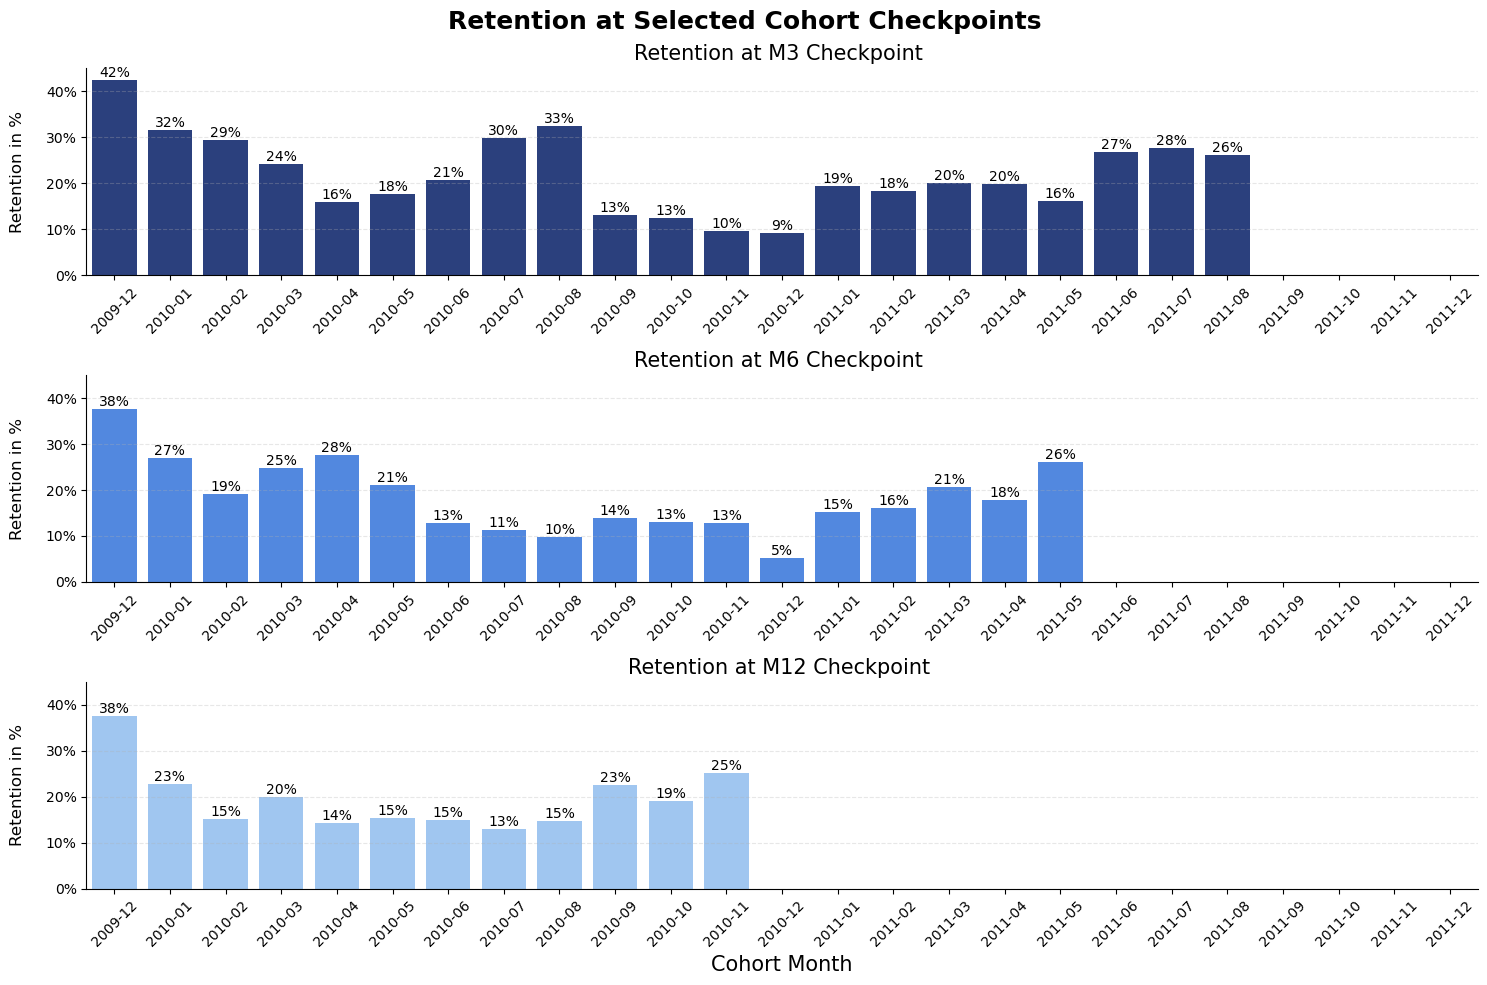

In [138]:
fig, axes = plt.subplots(3, 1, figsize=(15, 10))

fig.suptitle('Retention at Selected Cohort Checkpoints', fontsize=18, fontweight='bold')

sns.barplot(
    data=checkpoints[checkpoints['Checkpoint'] == 3],
    x='CohortMonth',
    y='Retention',
    color= '#1E3A8A',
    ax = axes[0]
)

axes[0].set_title("Retention at M3 Checkpoint ", fontsize=15)
axes[0].set_xlabel("")
axes[0].set_ylabel("Retention in %",fontsize=12, labelpad=15)
axes[0].grid(axis='y', alpha=0.3, linestyle='--')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt= lambda x: f'{x*100:.0f}%', fontsize=10)

axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=checkpoints[checkpoints['Checkpoint'] == 6],
    x='CohortMonth',
    y='Retention',
    color= '#3B82F6',
    ax = axes[1]
)

axes[1].set_title("Retention at M6 Checkpoint ", fontsize=15)
axes[1].set_xlabel("")
axes[1].set_ylabel("Retention in %",fontsize=12, labelpad=15)
axes[1].grid(axis='y', alpha=0.3, linestyle='--')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt= lambda x: f'{x*100:.0f}%', fontsize=10)

axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
axes[1].tick_params(axis='x', rotation=45)

sns.barplot(
    data=checkpoints[checkpoints['Checkpoint'] == 12],
    x='CohortMonth',
    y='Retention',
    color= '#93C5FD',
    ax = axes[2]
)

axes[2].set_title("Retention at M12 Checkpoint ", fontsize=15)
axes[2].set_xlabel("Cohort Month", fontsize=15)
axes[2].set_ylabel("Retention in %",fontsize=12, labelpad=15)
axes[2].grid(axis='y', alpha=0.3, linestyle='--')
for container in axes[2].containers:
    axes[2].bar_label(container, fmt= lambda x: f'{x*100:.0f}%', fontsize=10)

axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
axes[2].tick_params(axis='x', rotation=45)

axes[0].set_ylim(0, 0.45)
axes[1].set_ylim(0, 0.45)
axes[2].set_ylim(0, 0.45)
sns.despine()
plt.tight_layout()
plt.show()

Powyższa analiza checkpointów pokazuje, że różnice pomiędzy kohortami widoczne wcześniej w M1 utrzymują się również w dalszych etapach cyklu życia klienta. Jednocześnie retencja nie zawsze zachowuje się jak stopniowy, monotoniczny spadek. Przykładowo kohorty 2010-07 i 2010-08 osiągają relatywnie wysoką retencję w M3 (30% i 33%), ale w M6 spada ona odpowiednio do 13% i 11%. Z drugiej strony kohorty 2010-09, 2010-10 i 2010-11 mają niską retencję w M3 (13%, 13% i 10%), ale w M12 osiągają odpowiednio 23%, 19% i 25%. Wskazuje to, że część klientów powraca do zakupów po dłuższych okresach bez aktywności, dlatego retencja w tym zbiorze nie powinna być interpretowana wyłącznie jako stopniowa utrata klientów.

Szczególnie słabo wypada kohorta 2010-12, która już w M1 osiągała najniższą retencję (9%), a następnie pozostaje na niskim poziomie również w M3 (9%) i M6 (5%). Jest to więc przykład kohorty, dla której niski poziom retencji obserwowany w pierwszym miesiącu utrzymuje się także w średnim okresie.

Warto również zwrócić uwagę na kohorty z drugiej połowy 2011 roku. W M3 kohorty 2011-06, 2011-07 i 2011-08 osiągają relatywnie wysoką retencję, odpowiednio 27%, 28% i 26%. Nie można jednak na tej podstawie stwierdzić ogólnej poprawy długoterminowej retencji w 2011 roku, ponieważ dla nowszych kohort nie ma jeszcze wystarczająco długiego okresu obserwacji.

Kohorta 2009-12 osiąga najwyższą retencję w M3, M6 i M12, ale jej wynik należy traktować oddzielnie zgodnie z wcześniejszymi uwagami apropo jej potencjalnej struktury.

Wyniki są spójne z wcześniejszą obserwacją możliwej sezonowości związanej z okresami świątecznymi. Wyższa aktywność części kohort w kolejnych miesiącach oraz późniejsze wzrosty retencji mogą wskazywać, że część klientów dokonuje zakupów w sposób nieregularny, potencjalnie związany z sezonowym charakterem sprzedaży. 

---

### Identyfikacja drugiego zakupu klienta

In [139]:
orders = (
    df_clean
    .groupby(['Customer ID', 'Invoice'], as_index=False)
    ['InvoiceDate']
    .min()
)
orders

,Customer ID,Invoice,InvoiceDate
0,12346.00,499763,2010-03-02 13:08:00
1,12346.00,513774,2010-06-28 13:53:00
2,12346.00,541431,2011-01-18 10:01:00
3,12347.00,529924,2010-10-31 14:20:00
4,12347.00,537626,2010-12-07 14:57:00
...,...,...,...
36589,18287.00,523290,2010-09-21 12:19:00
36590,18287.00,534346,2010-11-22 11:51:00
36591,18287.00,554065,2011-05-22 10:39:00
36592,18287.00,570715,2011-10-12 10:23:00


In [140]:
purchase_dates = (
    orders
    .sort_values(['Customer ID', 'InvoiceDate'])
    .groupby('Customer ID')['InvoiceDate']
    .agg(
        First_Purchase='first',
        Second_Purchase=lambda x: x.iloc[1] if len(x) > 1 else pd.NaT
    )
    .reset_index()
)

In [141]:
purchase_dates['Days_to_Second_Purchase'] =  purchase_dates['Second_Purchase'] - purchase_dates['First_Purchase'] 

In [142]:
purchase_dates['Days_to_Second_Purchase'].describe()

count                        4234
mean      99 days 00:21:56.230514
std      113 days 07:01:02.407429
min               0 days 00:00:00
25%              21 days 01:23:00
50%              56 days 22:51:00
75%             133 days 00:02:15
max             714 days 03:39:00
Name: Days_to_Second_Purchase, dtype: object

In [143]:
bins = [0, 7, 30, 60, 90, 180, float('inf')]
labels = ['0-7', '8-30', '31-60', '61-90', '91-180', '181+']

purchase_dates['Second_Purchase_Group'] = pd.cut(
    purchase_dates['Days_to_Second_Purchase'].dt.days,
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [144]:
group_counts  = purchase_dates['Second_Purchase_Group'].value_counts().sort_index()

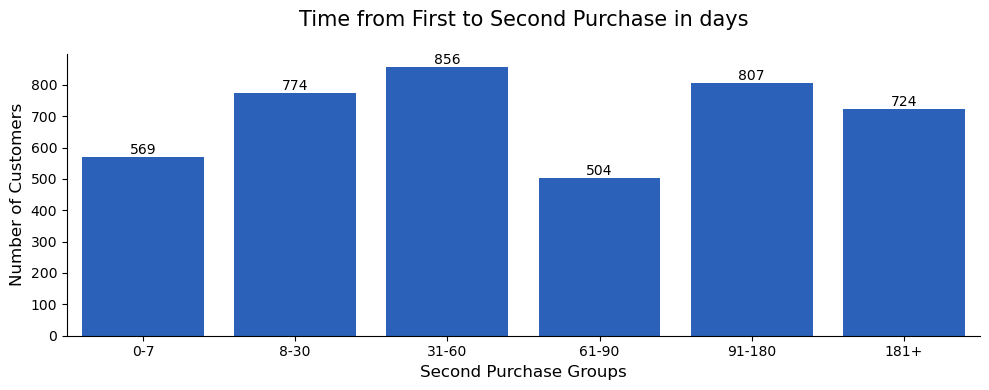

In [145]:
plt.figure(figsize=(10,4))

ax = sns.barplot(
    x=group_counts.index,
    y=group_counts.values,
    color="#145CCF"
                 )

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=10)

plt.title('Time from First to Second Purchase in days', fontsize = 15,pad=20)
plt.xlabel('Second Purchase Groups', fontsize=12)
plt.ylabel('Number of Customers',fontsize=12)

plt.tight_layout()
sns.despine()
plt.show()

Analiza czasu od pierwszego do drugiego zakupu pokazuje, że moment powrotu klientów jest mocno zróżnicowany. Mediana wynosi około 57 dni, co oznacza, że połowa klientów dokonujących drugiego zakupu wraca w ciągu około dwóch miesięcy. Największą grupę stanowią klienci, którzy dokonują drugiego zakupu w ciągu 31–60 dni (856 osób), natomiast 31,7% klientów wraca dopiero po ponad 90 dniach, a 17,1% wszystkich klientów z drugim zakupem wraca dopiero po ponad 180 dniach. Jednocześnie 13,4% klientów dokonuje drugiego zakupu już w ciągu pierwszych 7 dni. Wskazuje to, że klienci różnią się nie tylko prawdopodobieństwem powrotu, ale również tempem ponownego zakupu. Warto jednak zauważyć, że 1 618 klientów (27% wszystkich klientów) nie dokonało drugiego zakupu w ogóle w analizowanym okresie. 

### Podsumowanie analizy kohortowej 

Klienci nie zachowują się jednakowo po pierwszym zakupie. Część szybko dokonuje kolejnego zakupu, ale znaczna grupa wraca dopiero po kilku miesiącach. Różnice między kohortami są wyraźne, a ich wzorzec sugeruje sezonowość — szczególnie w okresie poprzedzającym sezon świąteczny, kiedy jednocześnie rośnie liczba nowych klientów i relatywnie wysoka jest retencja kolejnych kohort. Jednocześnie 2011 przynosi mniej nowych klientów niż 2010, ale wyższą retencję M1 w porównywalnych kohortach, co sugeruje, że spadek liczby nowych klientów nie musi oznaczać pogorszenia jakości pozyskiwanych klientów. Charakter zakupów w tym zbiorze — obejmujący również klientów hurtowych i produkty o charakterze prezentowym — może dodatkowo tłumaczyć nieregularność zakupów i dłuższe przerwy między kolejnymi transakcjami.

### Podsumowanie analizy RFM + Cohort na zbiorze Online Retail II

Wartość klientów jest silnie skoncentrowana — niewielka część bazy odpowiada za zdecydowaną większość sprzedaży. Jednocześnie analiza kohort wskazuje, że droga klienta do kolejnych zakupów jest bardzo zróżnicowana. Część klientów wraca szybko, ale znaczna część potrzebuje kilku miesięcy, a zachowanie kohort wyraźnie zmienia się w zależności od momentu pozyskania. Szczególnie widoczny jest powtarzający się wzrost aktywności klientów pozyskiwanych w drugiej połowie roku, co w przypadku sprzedaży giftware wskazuje na silny związek z sezonem świątecznym.

Z perspektywy biznesowej oznacza to, że nie wszyscy klienci powinni być traktowani w ten sam sposób. Największą uwagę należy poświęcić utrzymaniu klientów o wysokiej wartości, szczególnie grupie Champions i Loyal Customers, oraz selektywnemu odzyskiwaniu wartościowych klientów z grupy At Risk. Jednocześnie wyniki kohort sugerują, że działania mające zachęcić do kolejnego zakupu powinny uwzględniać moment pozyskania klienta i sezonowość sprzedaży, ponieważ prawdopodobieństwo oraz tempo powrotu nie są takie same w całym roku.

Analiza wskazuje również na istotną różnicę między pozyskiwaniem a utrzymaniem klientów. W 2011 roku liczba nowych klientów wyraźnie spadła względem 2010 roku, mimo że porównywalne kohorty osiągnęły wyższą retencję M1. Oznacza to, że spadku liczby nowych klientów nie można wyjaśnić wyłącznie pogorszeniem jakości pozyskiwanej bazy — problem wymagałby osobnej analizy źródeł i skuteczności akwizycji.

---

### Ograniczenia analizy RFM

In [146]:
# Nałożenie segmentów RFM na kohorty.
cohort_rfm = cohorts[['Customer ID','CohortMonth']].merge(rfm[['Segment']], left_on='Customer ID', right_index=True)
pd.crosstab(cohort_rfm['CohortMonth'], cohort_rfm['Segment'])

Segment,At Risk,Champions,Hibernating/Lost,Loyal Customers,Needs Attention,Potential Loyalists,Recent / Low-Frequency
CohortMonth,,,,,,,
2009-12,97,392,220,179,24,34,5
2010-01,45,89,115,91,11,15,2
2010-02,38,58,143,99,11,26,0
2010-03,31,79,185,106,11,23,6
2010-04,14,36,124,69,20,29,2
2010-05,11,31,128,36,13,29,7
2010-06,10,23,137,50,14,26,7
2010-07,6,26,93,33,14,11,2
2010-08,3,15,81,38,9,15,2


Segmentacja RFM opiera się wyłącznie na Recency, Frequency i Monetary liczonych względem końca okresu obserwacji — nie uwzględnia, kiedy klient dokonał pierwszego zakupu. W praktyce oznacza to, że segment Recent / Low-Frequency może zawierać dwa różne typy klientów: rzeczywiście nowych (pierwszy zakup niedawno) oraz klientów "uśpionych" — pozyskanych dawno temu, którzy po długiej przerwie dokonali drugiego zakupu blisko końca okresu obserwacji. Oba przypadki dają identyczny profil R/F w tabeli RFM (wysokie R, niskie F), mimo zupełnie innej historii relacji z firmą.

Dodatkowo, ze względu na dużą liczbę klientów z Frequency=1 (qcut z duplicates='drop'), próg F_score=1 obejmuje zarówno Frequency=1, jak i Frequency=2 — co jeszcze zwiększa szansę na wystąpienie tego zjawiska.

Powyższa tabela potwierdza obecność takich przypadków — część klientów oznaczonych jako Recent / Low-Frequency pochodzi z najwcześniejszych kohort (2009-12), mimo że ich relacja z firmą trwa już blisko dwa lata.

Jest to fundamentalne ograniczenie metody RFM w tej formie, a nie błąd implementacji — rozwiązaniem byłoby wzbogacenie segmentacji o zmienną tenure (czas od pierwszego zakupu) lub jawne rozróżnienie klientów jedno- i wielozakupowych, co stanowiłoby naturalne rozszerzenie tej analizy w kolejnej iteracji.

### Ograniczenia analizy kohortowej

Kohorta grudnia 2009 pozostaje trudna do jednoznacznej interpretacji — jako pierwszy miesiąc dostępnych danych może zawierać klientów aktywnych już wcześniej, co prawdopodobnie tłumaczy jej wyższą retencję względem pozostałych kohort.

Nowsze kohorty mają krótsze okno obserwacji, co uniemożliwia ich pełne porównanie ze starszymi w dłuższym horyzoncie (np. M12).

Porównania pojedynczych kohort w sekcji checkpointów mają charakter opisowy, nie statystyczny — w przeciwieństwie do zagregowanego testu M1 2010 vs 2011. Przy mniejszych kohortach różnice rzędu kilku punktów procentowych mogą częściowo wynikać z szumu.

Sugerowana sezonowość opiera się na zaledwie dwóch pełnych latach danych — zbyt krótkim okresie, by jednoznacznie odróżnić ją od przypadkowej zmienności między latami.